# Case: Your Electricity Bill - after Lesson 5

A running example that grows with the course. After each lesson, the case gets a new chapter that uses *exactly* the tools you have just learned - on **real, live data** about electricity prices and the Danish economy.


> ⚠️ **Important**: This is **not** an example of an exam-style task. It is an example of what the course's tools can do once you put them together. The purpose is inspiration and play - not syllabus material beyond what you have already learned.


### How to read the case

* Each chapter belongs to one lesson and only uses tools from the lessons up to and including it.
* Cells marked **Engine room** fetch data from the internet (Energi Data Service and Statistics Denmark). You do not need to understand the code inside them - they just hand over the numbers. If they cannot reach the internet, they automatically fall back to cached numbers, so the notebook always works.
* **You are allowed to change everything!** Change a number and run the cell again with Shift+Enter (or ▶). If later cells use the result, run those again too. If something breaks, just choose *Runtime → Restart session and run all* - and you are back at the start.
* Each chapter ends with **Turn the dials** - concrete suggestions for what you can change. That is where it gets fun.


## Today's electricity price

Electricity is traded on an exchange, hour by hour, the day before. The **spot price** is the raw market price (before taxes, transport, and VAT) - and it swings wildly over the course of a day. Let's fetch the latest available day's prices for western Denmark (DK1) and take a first look with a plot. Once we've covered functions and differentiation in Lesson 5, we will come back and read this curve's slope too.


In [1]:
#@title Engine room: defines the function fetch_electricity_prices(area) (you do not need to understand this cell)
import requests, json
import numpy as np

_CACHED_PRICES = [0.975, 0.959, 0.958, 0.937, 0.936, 0.984, 1.064, 1.1, 1.068, 0.942, 0.756, 0.496, 0.232, 0.125, 0.162, 0.348, 0.641, 0.863, 1.053, 1.273, 1.468, 1.458, 1.334, 1.239]
_CACHED_DATE = "2026-08-07"
_SOURCE_FALLBACK = "cached DK1 prices (fallback)"

def fetch_electricity_prices(area):
    # Fetches the most recent day's spot prices (kr/kWh) for a price area, e.g. "DK1"
    try:
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"limit": 200, "sort": "TimeDK desc",
                                 "filter": json.dumps({"PriceArea": [area]})}, timeout=10)
        records = r.json()["records"]
        date = records[0]["TimeDK"][:10]
        by_hour = {}
        for x in records:
            if x["TimeDK"][:10] == date:
                by_hour.setdefault(x["TimeDK"][11:13], []).append(x["DayAheadPriceDKK"])
        prices = [sum(v) / len(v) / 1000 for _, v in sorted(by_hour.items())]
        if len(prices) != 24:
            raise ValueError("incomplete day")
    except Exception:
        # The fallback ALWAYS returns the cached DK1 prices - regardless of which area was requested.
        # That is why the caller gets an honest source label back, so DK2 (or any other area)
        # can never be mistaken for real data for that area in a graph or a calculation.
        print(f"(Could not fetch live data for {area} - showing cached DK1 prices from {_CACHED_DATE} instead)")
        return np.array(_CACHED_PRICES), _CACHED_DATE, _SOURCE_FALLBACK
    print(f"Fetched fresh spot prices for {date} ({area})")
    return np.array(prices), date, f"live {area}"


In [2]:
# Fetch the latest available day's prices for western Denmark - the function comes from the engine room above
electricity_prices, date, source_dk1 = fetch_electricity_prices("DK1")

hours = np.arange(24)


Fetched fresh spot prices for 2026-08-14 (DK1)


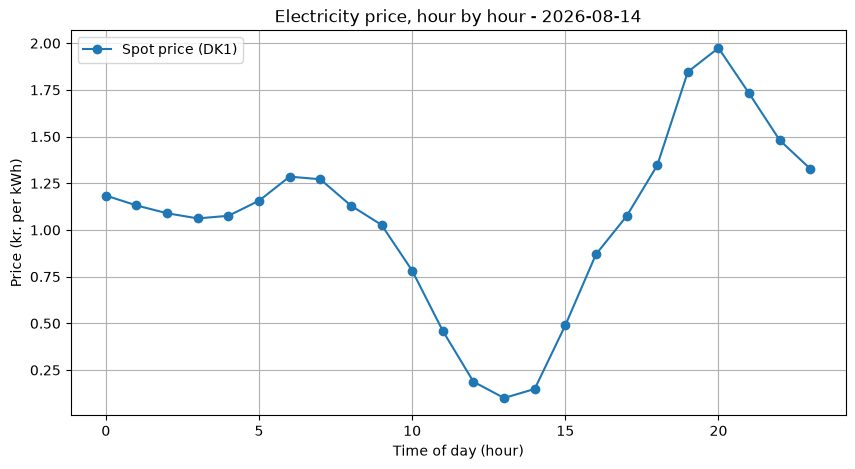

In [3]:
import matplotlib.pyplot as plt

# Plot the daily profile
plt.figure(figsize=(10, 5))
plt.plot(hours, electricity_prices, 'o-', label="Spot price (DK1)")
plt.title(f"Electricity price, hour by hour - {date}")
plt.xlabel("Time of day (hour)")
plt.ylabel("Price (kr. per kWh)")
plt.legend()
plt.grid(True)
plt.show()


Electricity prices follow the rhythm of society - and the seasons. In winter, the morning and evening hours are typically the most expensive. In summer, solar power can push the price right down in the middle of the day - sometimes even below zero. Look at **your** graph: when is electricity cheapest today, and where does the curve rise or fall most steeply?

We will come back to measure that steepness properly once we have covered functions and differentiation, in Chapter 5.


### West versus East - and the rest of the neighbourhood

The electricity market is split into price areas, and the function can fetch any of them - you just give it the name:

* `"DK1"` - Denmark **west** of the Great Belt (Storebælt) - Jutland and Funen, and Aalborg!
* `"DK2"` - Denmark **east** of the Great Belt - Zealand and Copenhagen
* `"NO2"` - southern Norway (hydropower!)
* `"SE3"` and `"SE4"` - central and southern Sweden
* `"DE"` - Germany

In Chapter 5, once we also have the tools to describe a curve's slope, we will fetch DK2 as well and compare the two areas head-to-head.


## Chapter 1 - Fixed or variable electricity agreement? *(after Lesson 1: Linear Equations)*

Two typical agreements (the numbers are illustrative - the spot price is real):

* **Fixed price**: no subscription fee, but 2.35 kr. per kWh - all year round.
* **Variable**: 49 kr. subscription per month + the spot price + a 0.65 kr. surcharge per kWh.

When is which cheaper? These are two linear functions - and the crossing point is a **system of linear equations**, which we solve exactly as in Lesson 1.

The prices here are the supplier's component of the bill - the full electricity bill also has grid tariffs, taxes, and VAT on top.


In [4]:
#@title Engine room: fetches the latest month's average spot price
_CACHED_AVG = 0.834

def fetch_month_average():
    try:
        from datetime import date, timedelta
        end_date = date.today()
        start_date = end_date - timedelta(days=30)
        r = requests.get("https://api.energidataservice.dk/dataset/DayAheadPrices",
                         params={"start": str(start_date), "end": str(end_date), "limit": 3000,
                                 "filter": json.dumps({"PriceArea": ["DK1"]})}, timeout=15)
        records = r.json()["records"]
        average = sum(x["DayAheadPriceDKK"] for x in records) / len(records) / 1000
        print(f"Latest month's average spot price: {average:.2f} kr/kWh")
        return average
    except Exception:
        print(f"(Could not fetch live data - using cached average: {_CACHED_AVG} kr/kWh)")
        return _CACHED_AVG

spot_average = fetch_month_average()


Latest month's average spot price: 0.85 kr/kWh


In [5]:
from sympy import Matrix, linsolve, symbols

# Monthly price as a function of consumption f (kWh):
#   Fixed price: price = 2.35*f          ->  2.35*f - price = 0
#   Variable:    price = 49 + a*f        ->  a*f - price = -49
a = spot_average + 0.65

f, price = symbols('f price')
intersection = linsolve(Matrix(([2.35, -1, 0], [a, -1, -49])), (f, price))
print(f"The agreements cost the same at {list(intersection)[0][0]:.0f} kWh/month ({list(intersection)[0][1]:.0f} kr./month)")

# Same answer with NumPy (Lesson 1)
A_sys = np.array([[2.35, -1], [a, -1]])
b_sys = np.array([0, -49])
np.linalg.solve(A_sys, b_sys)


The agreements cost the same at 57 kWh/month (135 kr./month)


array([ 57.47075311, 135.0562698 ])

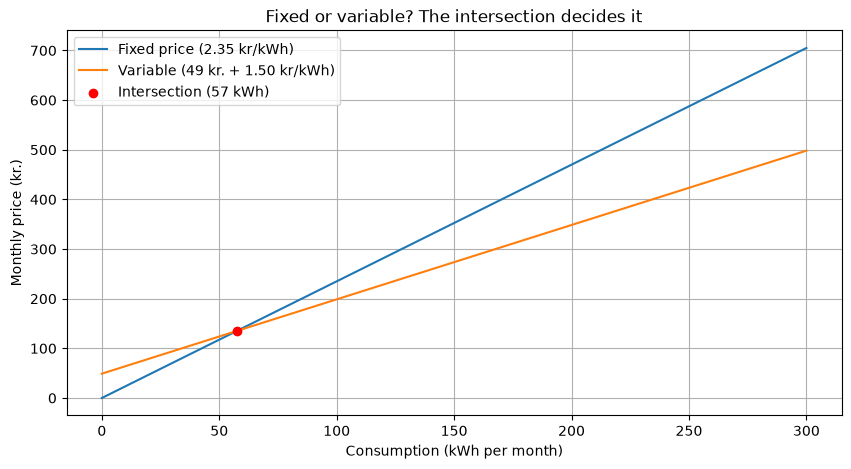

A typical apartment uses 125-175 kWh/month - read off for yourself which agreement wins right now


In [6]:
# Visualise the intersection point
consumption = np.linspace(0, 300, 100)
plt.figure(figsize=(10, 5))
plt.plot(consumption, 2.35 * consumption, label="Fixed price (2.35 kr/kWh)")
plt.plot(consumption, 49 + a * consumption, label=f"Variable (49 kr. + {a:.2f} kr/kWh)")

# The intersection only exists if the variable price per kWh (a) is actually LOWER than the fixed price.
# If a >= 2.35, the variable agreement is more expensive at every consumption level (it also has a
# subscription fee on top) - so the lines never cross for a positive consumption, and x_intersection
# would become meaninglessly negative.
if a >= 2.35:
    print(f"With a = {a:.2f} kr/kWh the variable agreement is more expensive than the fixed price at every consumption level -")
    print("there is no intersection: the fixed-price agreement wins at every consumption level with these prices.")
else:
    x_intersection = 49 / (2.35 - a)
    plt.scatter(x_intersection, 2.35 * x_intersection, color="red", zorder=5, label=f"Intersection ({x_intersection:.0f} kWh)")

plt.title("Fixed or variable? The intersection decides it")
plt.xlabel("Consumption (kWh per month)")
plt.ylabel("Monthly price (kr.)")
plt.legend()
plt.grid(True)
plt.show()

print("A typical apartment uses 125-175 kWh/month - read off for yourself which agreement wins right now")


#### Turn the dials

* **No subscription fee**: Change `49` to `0` in both the calculation cell and the plot cell, and run them again - where does the intersection move to?
* **Back to 2022**: Add the line `spot_average = 2.10` as a new top line in the calculation cell, and run both cells again. Back then, the picture looked completely different.


## Chapter 2 - Your consumption as a vector *(after Lesson 2: Vectors)*

Your daily consumption is a **vector**: 24 numbers, one per hour. Today's electricity prices are also a vector. And your daily bill? It is the **dot product** of the two - exactly as in Lesson 2.


In [7]:
# Two daily profiles (kWh per hour) - RAW shape, normalised below to the same daily consumption
early_bird_raw = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.3, 0.8, 0.9, 0.6, 0.3, 0.2, 0.2,
                           0.2, 0.2, 0.2, 0.3, 0.5, 0.8, 0.9, 0.6, 0.4, 0.3, 0.2, 0.1])
night_owl_raw = np.array([0.4, 0.3, 0.2, 0.1, 0.1, 0.1, 0.1, 0.2, 0.3, 0.3, 0.3, 0.3,
                      0.3, 0.3, 0.3, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.8, 0.6])

# Scale both profiles to EXACTLY the same daily consumption, so that only the SHAPE (when the
# electricity is used) distinguishes the two households - not the total amount
daily_consumption = 8.0  # kWh
early_bird = early_bird_raw / np.sum(early_bird_raw) * daily_consumption
night_owl = night_owl_raw / np.sum(night_owl_raw) * daily_consumption

print(f"Early bird: {np.sum(early_bird):.1f} kWh/day - Night owl: {np.sum(night_owl):.1f} kWh/day")


Early bird: 8.0 kWh/day - Night owl: 8.0 kWh/day


In [8]:
# The daily bill = consumption vector . price vector (the dot product from Lesson 2)
cost_early_bird = early_bird @ electricity_prices
cost_night_owl = night_owl @ electricity_prices

print(f"The early bird's day: {cost_early_bird:.2f} kr.")
print(f"The night owl's day: {cost_night_owl:.2f} kr.")
print(f"Difference: {abs(cost_early_bird - cost_night_owl):.2f} kr. - for EXACTLY the same amount of electricity")


The early bird's day: 9.31 kr.
The night owl's day: 9.69 kr.
Difference: 0.38 kr. - for EXACTLY the same amount of electricity


10% less consumption: 8.38 kr. (before: 9.31 kr.)


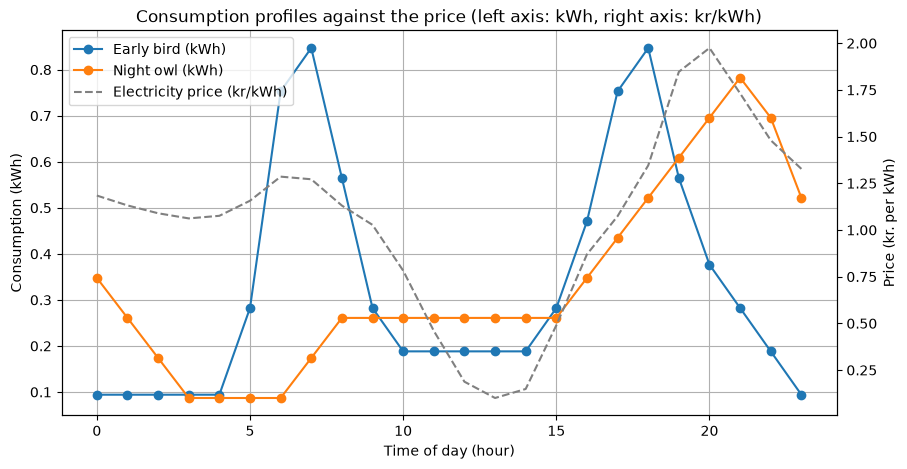

In [9]:
# Scalar multiplication: save 10% across the board
savings_profile = 0.9 * early_bird
print(f"10% less consumption: {savings_profile @ electricity_prices:.2f} kr. (before: {cost_early_bird:.2f} kr.)")

# Visualise the profiles against the price - two Y axes, since kWh and kr/kWh are not the same unit
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(hours, early_bird, 'o-', color='tab:blue', label="Early bird (kWh)")
ax1.plot(hours, night_owl, 'o-', color='tab:orange', label="Night owl (kWh)")
ax1.set_xlabel("Time of day (hour)")
ax1.set_ylabel("Consumption (kWh)")

ax2 = ax1.twinx()
ax2.plot(hours, electricity_prices, '--', color='gray', label="Electricity price (kr/kWh)")
ax2.set_ylabel("Price (kr. per kWh)")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

plt.title("Consumption profiles against the price (left axis: kWh, right axis: kr/kWh)")
ax1.grid(True)
plt.show()


#### Turn the dials

* **Your own profile**: Create a new cell (the `+ Code` button), copy in the lines with `early_bird = np.array([...])`, rename it to `my_profile`, and adjust the 24 numbers so they resemble your own day. Then calculate your daily bill: `print(my_profile @ electricity_prices)`.
* **Move 1 kWh**: In the `night_owl` vector, the number for 21:00 is the 22nd number in the row. Make it `0.5` smaller, make the number for 03:00 (the 4th number) `0.5` bigger, and run the cells again. How much does the night owl save by shifting consumption?


## Chapter 3 - A whole year through one multiplication *(after Lesson 3: Matrix Multiplication)*

Now we scale up. We fetch **8,760 hourly prices** - a full year of hourly data (the most recent complete year at hourly resolution, October 2024 to September 2025; since then prices have been published per quarter-hour). Also worth noting: the price can actually be *negative*, when wind turbines produce more than Denmark can use.

Three households, 365 days, 24 hours: with Lesson 3's **matrix multiplication** we calculate all three households' costs for every single day of the year - in a single operation.


In [10]:
#@title Engine room: fetches a whole year of hourly prices (8760 numbers)
_CACHED_YEAR_PRICES = [0.024, 0.001, 0.0, 0.0, 0.001, 0.051, 0.25, 0.294, 0.308, 0.309, 0.288, 0.261, 0.261, 0.261, 0.261, 0.296, 0.325, 0.393, 0.406, 0.421, 0.367, 0.345, 0.322, 0.31, 0.433, 0.367, 0.374, 0.365, 0.363, 0.363, 0.596, 0.693, 0.914, 0.701, 0.485, 0.394, 0.431, 0.597, 0.585, 0.607, 0.608, 0.746, 0.873, 0.97, 0.853, 0.72, 0.696, 0.634, 0.502, 0.491, 0.486, 0.479, 0.477, 0.48, 0.488, 0.547, 0.572, 0.544, 0.517, 0.47, 0.351, 0.253, 0.292, 0.383, 0.493, 0.669, 0.821, 0.86, 0.808, 0.737, 0.678, 0.608, 0.551, 0.541, 0.538, 0.537, 0.54, 0.575, 0.768, 0.944, 1.055, 0.867, 0.747, 0.634, 0.56, 0.548, 0.566, 0.59, 0.67, 0.799, 0.984, 1.112, 0.923, 0.745, 0.745, 0.671, 0.694, 0.631, 0.607, 0.563, 0.565, 0.595, 0.643, 0.749, 0.825, 0.768, 0.615, 0.509, 0.384, 0.29, 0.324, 0.419, 0.544, 0.69, 1.03, 1.029, 0.8, 0.705, 0.634, 0.5, 0.485, 0.452, 0.441, 0.433, 0.424, 0.433, 0.432, 0.525, 0.491, 0.448, 0.263, 0.124, 0.08, 0.042, 0.016, 0.013, 0.396, 0.617, 0.792, 0.725, 0.544, 0.443, 0.437, 0.385, 0.258, 0.263, 0.248, 0.225, 0.261, 0.292, 0.335, 0.378, 0.414, 0.384, 0.372, 0.356, 0.341, 0.322, 0.358, 0.458, 0.662, 0.874, 1.405, 1.405, 0.909, 0.745, 0.685, 0.59, 0.539, 0.5, 0.477, 0.445, 0.445, 0.503, 0.641, 0.823, 0.792, 0.634, 0.599, 0.547, 0.496, 0.529, 0.565, 0.578, 0.694, 0.85, 1.074, 1.142, 0.853, 0.708, 0.646, 0.504, 0.462, 0.447, 0.429, 0.405, 0.427, 0.476, 0.647, 0.826, 0.828, 0.649, 0.538, 0.447, 0.446, 0.446, 0.504, 0.576, 0.708, 0.876, 0.914, 0.948, 0.828, 0.714, 0.709, 0.614, 0.456, 0.35, 0.282, 0.239, 0.221, 0.295, 0.463, 0.633, 0.6, 0.503, 0.388, 0.29, 0.163, 0.119, 0.149, 0.277, 0.277, 0.285, 0.294, 0.288, 0.275, 0.264, 0.224, 0.236, 0.259, 0.259, 0.262, 0.268, 0.268, 0.274, 0.308, 0.439, 0.594, 0.401, 0.368, 0.325, 0.316, 0.31, 0.299, 0.298, 0.299, 0.497, 0.939, 1.208, 0.895, 0.744, 0.734, 0.655, 0.672, 0.593, 0.564, 0.56, 0.537, 0.507, 0.534, 0.4, 0.378, 0.311, 0.263, 0.256, 0.185, 0.107, 0.174, 0.263, 0.219, 0.424, 0.362, 0.299, 0.289, 0.288, 0.26, 0.189, 0.0, -0.0, -0.001, -0.003, -0.004, -0.001, -0.0, 0.013, 0.134, 0.073, 0.037, 0.046, 0.048, 0.053, 0.059, 0.095, 0.118, 0.166, 0.267, 0.403, 0.295, 0.287, 0.299, 0.275, 0.277, 0.263, 0.262, 0.256, 0.293, 0.464, 0.737, 0.974, 1.142, 0.88, 0.753, 0.696, 0.643, 0.616, 0.553, 0.65, 0.789, 1.183, 1.865, 1.964, 1.179, 0.851, 0.744, 0.707, 0.681, 0.645, 0.659, 0.627, 0.603, 0.668, 0.855, 1.383, 1.318, 0.825, 0.692, 0.62, 0.585, 0.535, 0.566, 0.622, 0.664, 0.9, 1.021, 0.726, 0.569, 0.497, 0.445, 0.304, 0.174, 0.096, 0.04, 0.027, 0.024, 0.061, 0.301, 0.354, 0.406, 0.355, 0.199, 0.106, 0.031, 0.015, 0.03, 0.106, 0.246, 0.263, 0.277, 0.272, 0.267, 0.258, 0.242, 0.198, 0.127, 0.091, 0.078, 0.042, 0.075, 0.216, 0.262, 0.299, 0.307, 0.302, 0.287, 0.287, 0.291, 0.305, 0.323, 0.474, 0.691, 0.893, 1.292, 1.276, 0.877, 0.73, 0.664, 0.613, 0.604, 0.606, 0.617, 0.588, 0.606, 0.629, 0.738, 1.117, 1.166, 0.828, 0.714, 0.636, 0.619, 0.598, 0.606, 0.629, 0.771, 0.997, 1.352, 1.064, 0.77, 0.722, 0.696, 0.638, 0.649, 0.619, 0.596, 0.561, 0.566, 0.573, 0.597, 0.685, 0.669, 0.631, 0.588, 0.547, 0.493, 0.455, 0.476, 0.59, 0.732, 0.814, 1.013, 0.887, 0.722, 0.673, 0.625, 0.547, 0.403, 0.409, 0.407, 0.417, 0.444, 0.242, 0.24, 0.291, 0.36, 0.341, 0.048, 0.001, 0.0, -0.007, -0.015, 0.0, 0.038, 0.414, 0.318, 0.269, 0.253, 0.156, 0.091, 0.014, -0.001, -0.001, -0.001, -0.001, -0.0, 0.024, 0.033, 0.301, 0.292, 0.24, 0.215, 0.209, 0.188, 0.21, 0.169, 0.435, 0.67, 0.97, 1.582, 1.405, 0.958, 0.75, 0.729, 0.693, 0.667, 0.653, 0.639, 0.624, 0.619, 0.641, 0.732, 1.119, 1.215, 0.846, 0.737, 0.639, 0.247, 0.233, 0.226, 0.23, 0.263, 0.759, 1.044, 1.177, 0.85, 0.698, 0.714, 0.659, 0.603, 0.621, 0.612, 0.621, 0.64, 0.676, 0.781, 1.025, 1.206, 0.958, 0.776, 0.694, 0.601, 0.575, 0.562, 0.658, 0.696, 1.01, 1.429, 1.313, 0.833, 0.755, 0.768, 0.695, 0.647, 0.597, 0.582, 0.564, 0.532, 0.598, 0.748, 1.058, 1.233, 0.875, 0.76, 0.694, 0.626, 0.59, 0.608, 0.714, 0.81, 0.922, 1.034, 0.852, 0.721, 0.698, 0.67, 0.624, 0.615, 0.612, 0.594, 0.616, 0.63, 0.706, 0.813, 0.923, 1.123, 0.913, 0.807, 0.701, 0.605, 0.583, 0.615, 0.741, 0.881, 1.184, 1.696, 1.379, 0.924, 0.868, 0.85, 0.801, 0.86, 0.818, 0.798, 0.804, 0.789, 0.797, 0.85, 0.938, 0.94, 0.877, 0.756, 0.608, 0.51, 0.472, 0.482, 0.608, 0.751, 0.938, 1.126, 0.886, 0.72, 0.662, 0.653, 0.572, 0.688, 0.627, 0.6, 0.614, 0.593, 0.588, 0.635, 0.666, 0.657, 0.629, 0.496, 0.408, 0.317, 0.298, 0.298, 0.48, 0.753, 0.879, 1.107, 1.087, 0.974, 0.881, 0.831, 0.82, 0.651, 0.713, 0.667, 0.628, 0.592, 0.596, 0.702, 0.738, 0.97, 0.95, 0.867, 0.728, 0.734, 0.708, 0.756, 0.85, 0.906, 0.927, 1.053, 1.11, 1.09, 0.927, 0.862, 0.82, 0.764, 0.756, 0.746, 0.737, 0.732, 0.746, 0.844, 0.95, 1.176, 1.129, 0.967, 0.9, 0.843, 0.786, 0.878, 1.014, 1.285, 1.587, 2.132, 1.92, 1.52, 1.049, 0.916, 0.867, 0.769, 0.744, 0.735, 0.646, 0.501, 0.478, 0.495, 0.543, 0.743, 0.773, 0.729, 0.469, 0.441, 0.415, 0.389, 0.633, 0.751, 1.062, 1.366, 1.439, 1.189, 0.817, 0.773, 0.81, 0.745, 0.785, 0.735, 0.721, 0.707, 0.658, 0.636, 0.656, 0.739, 0.646, 0.301, 0.155, 0.11, 0.093, 0.119, 0.118, 0.116, 0.116, 0.143, 0.125, 0.109, 0.093, 0.066, 0.053, 0.042, 0.024, 0.016, 0.013, 0.012, 0.011, 0.013, 0.024, 0.03, 0.033, 0.025, 0.024, 0.024, 0.024, 0.024, 0.024, 0.025, 0.077, 0.103, 0.149, 0.098, 0.109, 0.114, 0.149, 0.183, 0.462, 0.596, 0.662, 0.641, 0.648, 0.677, 0.72, 0.746, 0.754, 0.818, 0.68, 0.704, 0.661, 0.682, 0.771, 0.912, 1.026, 1.182, 1.118, 1.006, 0.916, 0.83, 0.792, 0.75, 0.755, 0.718, 0.661, 0.634, 0.57, 0.477, 0.417, 0.341, 0.298, 0.29, 0.25, 0.238, 0.235, 0.248, 0.437, 0.511, 0.667, 0.721, 0.719, 0.705, 0.657, 0.647, 0.665, 0.689, 0.686, 0.671, 0.672, 0.67, 0.677, 0.735, 0.931, 1.081, 1.024, 0.896, 0.777, 0.698, 0.71, 0.734, 0.746, 0.96, 1.323, 2.012, 1.772, 1.206, 0.917, 0.821, 0.783, 0.691, 0.624, 0.701, 0.676, 0.681, 0.701, 0.717, 0.79, 1.022, 1.016, 0.882, 0.79, 0.711, 0.708, 0.74, 0.817, 1.147, 2.4, 3.527, 3.214, 2.389, 1.266, 0.969, 0.878, 0.76, 0.745, 0.739, 0.712, 0.715, 0.717, 0.693, 0.902, 1.609, 1.447, 1.059, 0.983, 0.911, 0.909, 0.926, 1.021, 1.422, 2.244, 4.102, 2.499, 1.838, 1.199, 0.962, 0.843, 0.714, 0.671, 0.662, 0.653, 0.649, 0.508, 0.68, 0.76, 1.29, 1.424, 1.14, 1.11, 1.005, 1.007, 0.991, 1.044, 1.334, 1.811, 2.768, 2.071, 1.281, 0.965, 0.849, 0.833, 0.745, 0.522, 0.49, 0.434, 0.43, 0.325, 0.521, 0.754, 0.951, 0.991, 0.943, 0.875, 0.822, 0.787, 0.715, 0.713, 0.715, 0.963, 0.959, 0.753, 0.577, 0.299, 0.289, 0.289, 0.281, 0.784, 0.745, 0.731, 0.721, 0.734, 0.751, 0.778, 0.819, 0.851, 0.855, 0.82, 0.793, 0.797, 0.805, 0.822, 0.906, 1.023, 1.096, 1.102, 1.043, 0.957, 0.88, 0.854, 0.821, 0.783, 0.763, 0.761, 0.752, 0.752, 0.76, 0.748, 0.764, 0.786, 0.828, 0.84, 0.821, 0.827, 0.81, 0.838, 0.941, 0.999, 1.109, 1.089, 1.034, 0.934, 0.86, 0.828, 0.806, 0.818, 0.773, 0.746, 0.73, 0.727, 0.775, 0.863, 0.957, 1.007, 0.991, 0.958, 0.926, 0.894, 0.962, 0.973, 1.037, 1.051, 1.142, 1.097, 0.997, 0.909, 0.842, 0.832, 0.786, 0.823, 0.78, 0.766, 0.775, 0.802, 0.88, 1.101, 1.383, 1.504, 1.647, 1.419, 1.276, 1.205, 1.167, 1.3, 1.631, 2.034, 2.371, 1.68, 1.278, 1.112, 0.984, 0.934, 0.862, 0.874, 0.833, 0.804, 0.801, 0.805, 0.853, 0.972, 1.229, 1.682, 1.596, 1.416, 1.266, 1.165, 1.15, 1.144, 1.209, 1.265, 1.324, 1.297, 1.113, 0.693, 0.549, 0.376, 0.299, 0.384, 0.361, 0.365, 0.369, 0.319, 0.379, 0.613, 0.753, 0.87, 0.837, 0.81, 0.833, 0.851, 0.95, 1.0, 1.061, 1.1, 1.163, 1.149, 1.106, 1.034, 0.966, 0.917, 0.839, 0.774, 0.762, 0.747, 0.746, 0.667, 0.667, 0.703, 0.953, 1.097, 1.025, 0.998, 0.799, 0.762, 0.718, 0.709, 0.709, 0.71, 0.743, 0.573, 0.298, 0.293, 0.268, 0.259, 0.24, 0.142, 0.041, 0.036, 0.035, 0.036, 0.036, 0.038, 0.125, 0.166, 0.216, 0.261, 0.179, 0.163, 0.149, 0.18, 0.259, 0.291, 0.351, 0.337, 0.297, 0.261, 0.286, 0.221, 0.148, 0.123, 0.129, 0.224, 0.204, 0.162, 0.186, 0.226, 0.231, 0.2, 0.205, 0.145, 0.111, 0.112, 0.111, 0.236, 0.241, 0.283, 0.293, 0.288, 0.28, 0.268, 0.26, 0.246, 0.214, 0.407, 0.401, 0.318, 0.315, 0.319, 0.268, 0.442, 0.702, 0.864, 0.753, 0.63, 0.596, 0.559, 0.507, 0.592, 0.785, 0.907, 1.097, 1.207, 1.132, 0.952, 0.877, 0.873, 0.809, 0.799, 0.756, 0.713, 0.684, 0.711, 0.728, 0.867, 0.985, 1.158, 1.177, 1.166, 1.14, 1.106, 1.076, 1.046, 0.963, 0.991, 1.046, 1.004, 0.939, 0.874, 0.816, 0.785, 0.67, 0.747, 0.686, 0.646, 0.608, 0.611, 0.696, 0.802, 0.998, 1.066, 1.044, 0.898, 0.804, 0.726, 0.726, 0.792, 0.953, 0.998, 1.059, 1.064, 1.046, 1.014, 0.918, 0.868, 0.772, 0.701, 0.674, 0.647, 0.628, 0.628, 0.69, 0.799, 0.906, 0.992, 1.007, 0.95, 0.861, 0.847, 0.901, 1.056, 1.155, 1.305, 1.359, 1.203, 1.149, 0.98, 0.918, 0.917, 0.802, 0.866, 0.792, 0.73, 0.681, 0.661, 0.687, 0.873, 1.009, 1.115, 1.076, 1.024, 0.896, 0.789, 0.71, 0.717, 0.792, 0.829, 0.958, 1.002, 0.961, 0.792, 0.742, 0.65, 0.571, 0.458, 0.392, 0.378, 0.357, 0.367, 0.368, 0.377, 0.501, 0.651, 0.639, 0.586, 0.548, 0.531, 0.566, 0.639, 0.75, 0.642, 0.71, 0.632, 0.53, 0.444, 0.358, 0.292, 0.138, 0.012, 0.013, 0.002, 0.003, 0.002, 0.002, 0.003, 0.004, 0.013, 0.028, 0.017, 0.02, 0.017, 0.02, 0.023, 0.049, 0.104, 0.116, 0.121, 0.09, 0.055, 0.034, 0.024, 0.0, -0.009, -0.012, -0.011, -0.014, -0.011, -0.002, 0.0, 0.406, 0.452, 0.302, 0.317, 0.309, 0.298, 0.364, 0.347, 0.301, 0.313, 0.353, 0.347, 0.305, 0.29, 0.228, 0.197, 0.298, 0.12, 0.138, 0.15, 0.137, 0.139, 0.147, 0.284, 0.295, 0.306, 0.298, 0.3, 0.298, 0.298, 0.3, 0.306, 0.352, 0.355, 0.356, 0.355, 0.311, 0.353, 0.355, 0.318, 0.383, 0.781, 0.793, 0.82, 0.77, 0.752, 0.836, 0.817, 1.105, 1.272, 1.184, 1.142, 1.119, 1.086, 1.048, 0.97, 0.982, 0.878, 0.83, 0.838, 0.76, 0.583, 0.536, 0.5, 0.364, 0.367, 0.307, 0.246, 0.239, 0.236, 0.39, 0.472, 0.653, 0.761, 0.714, 0.663, 0.647, 0.627, 0.625, 0.71, 0.795, 0.989, 1.114, 1.18, 1.148, 1.074, 0.988, 0.911, 0.84, 0.823, 0.798, 0.772, 0.767, 0.785, 0.86, 1.014, 1.222, 1.294, 1.174, 1.032, 0.895, 0.821, 0.852, 0.815, 0.915, 0.915, 1.077, 1.059, 0.976, 0.894, 0.836, 0.848, 0.77, 0.597, 0.452, 0.386, 0.294, 0.289, 0.277, 0.283, 0.299, 0.306, 0.313, 0.312, 0.317, 0.314, 0.41, 0.666, 0.742, 0.858, 1.021, 1.014, 0.969, 0.868, 0.837, 0.856, 0.796, 0.71, 0.671, 0.657, 0.639, 0.629, 0.597, 0.621, 0.665, 0.74, 0.706, 0.666, 0.614, 0.636, 0.62, 0.676, 0.767, 0.876, 0.82, 0.757, 0.623, 0.502, 0.439, 0.374, 0.339, 0.166, 0.202, 0.235, 0.235, 0.237, 0.285, 0.399, 0.423, 0.496, 0.487, 0.485, 0.485, 0.501, 0.523, 0.679, 0.808, 0.997, 1.097, 1.103, 1.029, 0.861, 0.746, 0.711, 0.662, 0.712, 0.678, 0.656, 0.647, 0.708, 0.713, 0.895, 1.059, 1.109, 0.961, 0.754, 0.708, 0.708, 0.71, 1.076, 1.223, 1.486, 1.56, 1.476, 1.416, 1.256, 1.142, 1.06, 0.976, 0.902, 0.87, 0.841, 0.821, 0.833, 0.892, 1.048, 1.527, 2.005, 1.82, 1.583, 1.484, 1.434, 1.437, 1.548, 1.699, 1.877, 2.146, 1.717, 1.447, 1.185, 0.992, 0.895, 0.828, 0.856, 0.789, 0.747, 0.65, 0.574, 0.579, 0.681, 0.858, 0.955, 0.745, 0.685, 0.598, 0.562, 0.529, 0.469, 0.461, 0.406, 0.45, 0.4, 0.333, 0.304, 0.347, 0.312, 0.322, 0.079, 0.034, 0.029, 0.017, 0.022, 0.077, 0.468, 0.691, 0.822, 0.822, 0.776, 0.734, 0.685, 0.751, 0.813, 0.872, 0.981, 1.066, 1.127, 1.063, 0.97, 0.891, 0.903, 0.762, 0.646, 0.554, 0.507, 0.465, 0.366, 0.279, 0.285, 0.309, 0.404, 0.441, 0.401, 0.383, 0.404, 0.406, 0.428, 0.441, 0.455, 0.47, 0.463, 0.515, 0.559, 0.569, 0.552, 0.513, 0.325, 0.325, 0.379, 0.309, 0.303, 0.298, 0.305, 0.329, 0.341, 0.5, 0.663, 0.775, 0.642, 0.72, 0.635, 0.593, 0.621, 0.618, 0.584, 0.483, 0.432, 0.408, 0.317, 0.304, 0.32, 0.337, 0.261, 0.255, 0.243, 0.285, 0.319, 0.515, 0.608, 0.498, 0.501, 0.511, 0.521, 0.589, 0.691, 0.841, 0.859, 0.887, 0.872, 0.911, 0.844, 0.753, 0.734, 0.689, 0.576, 0.634, 0.645, 0.624, 0.65, 0.664, 0.836, 1.008, 1.266, 1.358, 1.378, 1.391, 1.347, 1.423, 1.413, 1.474, 1.485, 1.487, 1.35, 1.344, 1.242, 1.127, 1.029, 0.905, 0.865, 0.807, 0.8, 0.792, 0.811, 0.935, 1.219, 1.861, 2.656, 2.722, 2.525, 2.568, 2.491, 2.485, 2.701, 2.812, 3.266, 3.243, 2.684, 2.545, 1.542, 1.277, 1.119, 1.014, 0.912, 0.86, 0.82, 0.801, 0.839, 0.922, 1.314, 4.474, 4.889, 4.823, 4.056, 3.47, 3.02, 3.097, 3.657, 4.985, 6.108, 6.982, 5.028, 4.109, 2.205, 1.263, 1.119, 1.005, 0.97, 0.917, 0.887, 0.857, 0.862, 0.938, 1.167, 1.4, 1.887, 1.833, 1.554, 1.301, 1.238, 1.231, 1.376, 1.647, 1.865, 2.12, 1.939, 1.683, 1.305, 1.091, 1.008, 0.869, 0.872, 0.83, 0.806, 0.738, 0.697, 0.657, 0.518, 0.582, 0.662, 0.554, 0.3, 0.277, 0.28, 0.273, 0.265, 0.262, 0.274, 0.279, 0.25, 0.262, 0.232, 0.194, 0.221, 0.22, 0.336, 0.263, 0.232, 0.233, 0.252, 0.27, 0.272, 0.337, 0.37, 0.317, 0.301, 0.292, 0.291, 0.286, 0.273, 0.263, 0.256, 0.234, 0.194, 0.167, 0.138, 0.104, 0.075, 0.017, 0.001, 0.001, 0.0, 0.001, 0.0, 0.013, 0.058, 0.22, 0.257, 0.237, 0.23, 0.224, 0.219, 0.217, 0.213, 0.246, 0.241, 0.231, 0.242, 0.221, 0.19, 0.167, 0.125, 0.124, 0.106, 0.15, 0.147, 0.154, 0.127, 0.124, 0.262, 0.334, 0.384, 0.421, 0.395, 0.382, 0.453, 0.476, 0.641, 0.801, 0.839, 0.95, 0.907, 0.806, 0.735, 0.715, 0.6, 0.453, 0.168, 0.228, 0.203, 0.122, 0.109, 0.067, 0.045, 0.291, 0.371, 0.323, 0.25, 0.244, 0.237, 0.234, 0.23, 0.245, 0.212, 0.219, 0.147, 0.129, 0.119, 0.133, 0.154, 0.16, 0.084, 0.099, 0.041, 0.014, 0.002, 0.015, 0.064, 0.403, 0.496, 0.503, 0.485, 0.428, 0.277, 0.233, 0.228, 0.231, 0.234, 0.23, 0.16, 0.059, 0.048, 0.052, 0.049, 0.081, 0.083, 0.134, 0.122, 0.13, 0.103, 0.067, 0.04, 0.203, 0.151, 0.225, 0.233, 0.238, 0.251, 0.25, 0.262, 0.33, 0.537, 0.656, 0.583, 0.367, 0.25, 0.231, 0.185, 0.149, 0.087, 0.167, 0.161, 0.145, 0.135, 0.15, 0.149, 0.158, 0.171, 0.219, 0.234, 0.231, 0.232, 0.223, 0.193, 0.204, 0.219, 0.218, 0.209, 0.155, 0.114, 0.039, 0.032, 0.03, 0.014, 0.011, 0.002, -0.001, -0.006, -0.0, -0.0, 0.017, 0.045, 0.154, 0.15, 0.172, 0.158, 0.16, 0.209, 0.312, 0.35, 0.488, 0.453, 0.434, 0.35, 0.273, 0.27, 0.183, 0.218, 0.15, 0.107, 0.068, 0.073, 0.11, 0.13, 0.388, 0.443, 0.445, 0.393, 0.388, 0.404, 0.409, 0.459, 0.55, 0.616, 0.733, 0.759, 0.727, 0.691, 0.808, 0.789, 0.723, 0.642, 0.618, 0.611, 0.582, 0.588, 0.601, 0.635, 0.752, 0.858, 0.902, 0.895, 0.881, 0.876, 0.861, 0.88, 0.891, 0.897, 0.88, 0.828, 0.776, 0.765, 0.706, 0.739, 0.658, 0.682, 0.645, 0.635, 0.512, 0.461, 0.468, 0.467, 0.634, 0.673, 0.74, 0.698, 0.691, 0.704, 0.679, 0.74, 0.841, 0.871, 0.899, 0.889, 0.88, 0.883, 0.843, 0.851, 0.778, 0.762, 0.709, 0.706, 0.669, 0.678, 0.71, 0.739, 0.84, 0.889, 0.882, 0.845, 0.791, 0.804, 0.775, 0.818, 0.901, 0.967, 1.029, 1.03, 1.013, 0.963, 0.902, 0.921, 0.873, 0.797, 0.757, 0.754, 0.744, 0.743, 0.792, 0.863, 0.927, 0.984, 0.971, 0.896, 0.805, 0.804, 0.805, 0.908, 1.018, 1.091, 1.133, 1.182, 1.093, 0.993, 0.936, 0.946, 0.851, 0.943, 0.87, 0.822, 0.79, 0.768, 0.788, 0.819, 0.927, 0.955, 0.957, 0.916, 0.846, 0.813, 0.821, 0.879, 1.006, 1.039, 1.125, 1.101, 1.048, 0.964, 0.939, 0.905, 0.857, 0.95, 0.851, 0.803, 0.759, 0.729, 0.736, 0.501, 0.429, 0.401, 0.305, 0.19, 0.179, 0.218, 0.212, 0.184, 0.184, 0.205, 0.21, 0.186, 0.181, 0.176, 0.173, 0.149, 0.091, 0.027, 0.1, 0.1, 0.124, 0.146, 0.13, 0.191, 0.255, 0.278, 0.271, 0.287, 0.286, 0.271, 0.258, 0.269, 0.279, 0.296, 0.292, 0.275, 0.246, 0.235, 0.234, 0.22, 0.266, 0.377, 0.342, 0.421, 0.26, 0.23, 0.225, 0.298, 0.387, 0.585, 0.623, 0.357, 0.317, 0.277, 0.271, 0.149, 0.127, 0.139, 0.156, 0.194, 0.187, 0.142, 0.117, 0.068, 0.004, 0.016, 0.012, 0.012, 0.008, 0.004, 0.0, 0.006, 0.006, 0.014, 0.016, 0.026, 0.028, 0.028, 0.028, 0.04, 0.092, 0.147, 0.165, 0.13, 0.076, 0.06, 0.05, 0.075, 0.052, 0.021, 0.02, 0.027, 0.052, 0.095, 0.224, 0.501, 0.737, 0.906, 0.949, 0.929, 0.832, 0.749, 0.784, 0.829, 0.941, 1.009, 1.117, 1.083, 0.801, 0.765, 0.581, 0.49, 0.371, 0.318, 0.284, 0.263, 0.249, 0.214, 0.233, 0.287, 0.389, 0.599, 0.559, 0.563, 0.465, 0.402, 0.391, 0.4, 0.54, 0.748, 0.786, 0.806, 0.749, 0.61, 0.6, 0.501, 0.559, 0.675, 0.674, 0.673, 0.683, 0.716, 0.762, 0.826, 0.895, 0.958, 0.975, 0.972, 0.957, 0.97, 0.969, 1.018, 1.035, 1.059, 1.128, 1.073, 1.029, 0.966, 0.916, 0.882, 0.817, 0.849, 0.748, 0.698, 0.7, 0.667, 0.623, 0.626, 0.616, 0.627, 0.657, 0.619, 0.662, 0.609, 0.578, 0.507, 0.378, 0.372, 0.473, 0.461, 0.378, 0.275, 0.274, 0.259, 0.21, 0.205, 0.144, 0.085, 0.069, 0.075, 0.11, 0.178, 0.237, 0.295, 0.269, 0.259, 0.245, 0.233, 0.213, 0.191, 0.196, 0.2, 0.236, 0.236, 0.209, 0.185, 0.103, 0.152, 0.075, 0.101, 0.065, 0.066, 0.037, 0.038, 0.043, 0.334, 0.284, 0.277, 0.261, 0.256, 0.258, 0.249, 0.248, 0.248, 0.248, 0.261, 0.287, 0.261, 0.247, 0.188, 0.149, 0.169, 0.277, 0.153, 0.174, 0.179, 0.172, 0.197, 0.212, 0.231, 0.347, 0.44, 0.501, 0.532, 0.552, 0.542, 0.582, 0.634, 0.786, 0.936, 1.14, 1.113, 1.084, 0.882, 0.751, 0.686, 0.682, 0.757, 0.746, 0.737, 0.71, 0.733, 0.766, 0.996, 1.11, 1.23, 1.165, 1.102, 1.046, 0.956, 0.904, 0.925, 0.954, 0.95, 0.986, 1.015, 0.966, 0.89, 0.783, 0.754, 0.658, 0.633, 0.599, 0.532, 0.515, 0.521, 0.626, 0.739, 0.925, 1.041, 1.022, 0.922, 0.848, 0.802, 0.783, 0.821, 0.96, 1.006, 1.064, 1.075, 1.052, 0.961, 0.818, 0.868, 0.82, 0.741, 0.758, 0.704, 0.667, 0.569, 0.501, 0.576, 0.706, 0.803, 0.77, 0.755, 0.679, 0.679, 0.679, 0.666, 0.765, 0.837, 0.894, 0.913, 0.857, 0.807, 0.782, 0.769, 0.789, 0.624, 0.625, 0.647, 0.628, 0.634, 0.625, 0.641, 0.759, 0.855, 0.896, 0.879, 0.788, 0.768, 0.743, 0.781, 0.886, 0.992, 1.052, 1.094, 1.072, 1.006, 0.951, 0.904, 0.857, 0.838, 0.784, 0.779, 0.749, 0.675, 0.445, 0.635, 0.91, 1.14, 0.859, 0.686, 0.503, 0.427, 0.419, 0.467, 0.423, 0.482, 0.501, 0.374, 0.301, 0.184, 0.171, 0.157, 0.133, 0.275, 0.298, 0.31, 0.315, 0.3, 0.345, 0.376, 0.45, 0.511, 0.47, 0.411, 0.419, 0.36, 0.389, 0.451, 0.425, 0.518, 0.551, 0.521, 0.463, 0.44, 0.443, 0.439, 0.514, 0.463, 0.472, 0.484, 0.579, 0.786, 0.857, 0.996, 1.431, 2.292, 2.35, 2.321, 2.274, 2.321, 2.308, 2.133, 1.958, 1.943, 2.203, 2.015, 1.666, 1.278, 0.965, 0.996, 0.661, 0.931, 0.827, 0.717, 0.437, 0.435, 0.501, 0.766, 0.939, 1.12, 1.059, 0.888, 0.552, 0.526, 0.507, 0.526, 0.648, 1.008, 1.201, 1.19, 0.66, 0.571, 0.519, 0.514, 0.474, 0.415, 0.431, 0.451, 0.451, 0.478, 0.522, 0.708, 0.81, 0.791, 0.721, 0.58, 0.518, 0.484, 0.476, 0.506, 0.556, 0.687, 1.25, 1.306, 1.251, 1.093, 1.021, 0.889, 0.772, 0.932, 0.903, 0.903, 0.887, 0.868, 0.894, 0.892, 0.784, 1.034, 1.075, 0.979, 0.907, 0.887, 0.858, 0.89, 0.995, 1.117, 1.228, 1.25, 1.252, 1.165, 1.07, 1.018, 0.965, 0.968, 0.927, 0.918, 0.905, 0.897, 0.895, 0.907, 0.92, 0.922, 0.934, 0.934, 0.907, 0.837, 0.802, 0.872, 0.942, 1.046, 1.117, 1.187, 1.168, 1.112, 1.039, 0.977, 0.917, 0.912, 0.891, 0.87, 0.854, 0.861, 0.952, 1.206, 2.063, 3.223, 2.176, 1.763, 1.399, 1.313, 1.279, 1.438, 2.068, 3.0, 4.353, 3.531, 2.205, 1.641, 1.268, 1.138, 1.029, 0.951, 0.908, 0.87, 0.85, 0.832, 0.795, 0.798, 1.234, 1.563, 1.569, 1.478, 1.205, 1.1, 1.066, 1.12, 1.294, 1.51, 2.108, 1.82, 1.492, 1.304, 1.158, 1.034, 0.818, 0.798, 0.758, 0.784, 0.775, 0.7, 0.802, 0.963, 1.459, 1.78, 1.488, 1.336, 1.29, 1.231, 1.268, 1.343, 1.46, 1.485, 1.559, 1.346, 1.247, 1.004, 0.953, 0.956, 0.844, 0.842, 0.812, 0.788, 0.746, 0.728, 0.746, 0.794, 1.019, 1.187, 1.16, 0.977, 0.866, 0.707, 0.623, 0.54, 0.504, 0.624, 0.68, 0.635, 0.581, 0.486, 0.428, 0.417, 0.332, 0.278, 0.298, 0.31, 0.282, 0.269, 0.275, 0.304, 0.524, 0.597, 0.444, 0.351, 0.312, 0.277, 0.187, 0.173, 0.174, 0.149, 0.201, 0.214, 0.154, 0.157, 0.149, 0.098, 0.075, 0.126, 0.158, 0.148, 0.203, 0.183, 0.158, 0.222, 0.352, 0.447, 0.497, 0.591, 0.539, 0.611, 0.612, 0.635, 0.773, 0.926, 1.034, 1.098, 1.077, 0.976, 0.946, 0.929, 0.858, 0.942, 0.864, 0.831, 0.797, 0.787, 0.769, 0.742, 0.79, 0.809, 0.884, 0.787, 0.765, 0.722, 0.672, 0.69, 0.833, 0.94, 0.991, 0.818, 0.616, 0.519, 0.443, 0.323, 0.178, 0.292, 0.263, 0.197, 0.105, 0.075, 0.161, 0.249, 0.383, 0.451, 0.288, 0.304, 0.276, 0.255, 0.268, 0.298, 0.352, 0.373, 0.403, 0.405, 0.375, 0.338, 0.302, 0.288, 0.281, 0.29, 0.284, 0.266, 0.284, 0.305, 0.318, 0.429, 0.79, 0.887, 0.858, 0.842, 0.812, 0.799, 0.813, 0.841, 0.934, 0.972, 1.043, 0.899, 0.822, 0.637, 0.538, 0.463, 0.379, 0.655, 0.622, 0.583, 0.565, 0.566, 0.601, 0.693, 1.055, 1.064, 0.974, 0.784, 0.666, 0.634, 0.638, 0.654, 0.767, 0.987, 1.116, 1.12, 1.035, 0.815, 0.768, 0.799, 0.741, 0.635, 0.626, 0.597, 0.569, 0.57, 0.705, 0.84, 0.971, 1.074, 1.032, 0.933, 0.801, 0.804, 0.818, 0.921, 1.05, 1.09, 1.29, 1.242, 1.135, 1.05, 0.941, 0.89, 0.82, 0.805, 0.708, 0.708, 0.699, 0.608, 0.555, 0.776, 1.149, 1.222, 1.155, 0.971, 0.942, 0.896, 0.904, 0.894, 1.118, 1.256, 1.382, 1.377, 1.336, 1.214, 1.139, 1.077, 0.981, 1.022, 0.962, 0.927, 0.889, 0.824, 0.742, 0.869, 0.936, 1.102, 1.063, 0.958, 0.896, 0.823, 0.772, 0.848, 0.956, 1.135, 1.241, 1.25, 1.216, 1.164, 1.084, 1.058, 0.983, 0.994, 0.947, 0.918, 0.9, 0.913, 0.921, 0.956, 1.014, 1.025, 1.027, 0.97, 0.965, 0.912, 0.835, 0.869, 0.955, 1.128, 1.224, 1.287, 1.298, 1.232, 1.089, 0.919, 0.908, 0.935, 0.945, 0.931, 0.896, 0.828, 0.872, 1.188, 1.551, 1.815, 1.328, 1.119, 0.941, 0.875, 0.86, 0.927, 1.08, 1.274, 1.612, 1.498, 1.498, 1.247, 1.071, 0.912, 0.698, 0.885, 0.9, 0.823, 0.727, 0.58, 0.601, 0.795, 1.158, 1.472, 1.124, 1.005, 0.842, 0.726, 0.642, 0.584, 0.603, 0.712, 0.745, 0.738, 0.642, 0.563, 0.507, 0.485, 0.394, 0.444, 0.436, 0.438, 0.436, 0.459, 0.566, 0.649, 0.737, 0.802, 0.749, 0.656, 0.512, 0.508, 0.51, 0.617, 0.7, 0.81, 0.973, 1.033, 1.027, 0.913, 0.864, 0.796, 0.681, 0.816, 0.87, 0.899, 0.915, 0.86, 0.912, 0.894, 1.296, 1.589, 1.325, 1.181, 1.009, 0.883, 0.879, 0.828, 0.97, 1.044, 1.269, 1.272, 1.213, 1.05, 0.978, 0.91, 0.858, 0.846, 0.81, 0.812, 0.783, 0.654, 0.67, 0.824, 1.055, 1.223, 1.119, 0.963, 0.746, 0.665, 0.665, 0.663, 0.645, 0.73, 0.8, 0.811, 0.684, 0.559, 0.514, 0.473, 0.474, 0.423, 0.42, 0.44, 0.433, 0.44, 0.44, 0.455, 0.47, 0.519, 0.493, 0.466, 0.432, 0.434, 0.461, 0.534, 0.652, 0.67, 0.837, 0.844, 0.806, 0.799, 0.844, 0.954, 0.84, 1.007, 0.97, 0.855, 0.89, 0.865, 0.844, 0.86, 0.892, 0.91, 0.896, 0.828, 0.775, 0.675, 0.649, 0.685, 0.783, 0.872, 0.97, 0.895, 0.787, 0.678, 0.644, 0.607, 0.537, 0.515, 0.486, 0.469, 0.476, 0.474, 0.501, 0.64, 0.861, 0.975, 0.903, 0.762, 0.621, 0.57, 0.565, 0.59, 0.585, 0.631, 0.654, 0.676, 0.583, 0.519, 0.502, 0.486, 0.477, 0.403, 0.417, 0.416, 0.419, 0.419, 0.447, 0.521, 0.609, 0.741, 0.642, 0.545, 0.531, 0.527, 0.541, 0.556, 0.581, 0.609, 0.7, 0.79, 0.671, 0.604, 0.595, 0.601, 0.573, 0.595, 0.587, 0.582, 0.58, 0.592, 0.605, 0.806, 1.112, 1.226, 1.179, 0.977, 0.849, 0.83, 0.875, 0.964, 1.026, 1.253, 1.365, 1.445, 1.426, 1.267, 1.134, 1.089, 0.876, 1.047, 1.027, 1.05, 1.019, 0.895, 0.891, 1.057, 1.416, 1.639, 1.601, 1.481, 1.335, 1.245, 1.06, 1.046, 1.07, 1.134, 1.477, 1.459, 1.336, 1.171, 1.088, 1.02, 0.934, 1.026, 0.991, 0.958, 0.952, 0.949, 1.041, 1.2, 1.694, 1.981, 1.605, 1.35, 1.216, 1.118, 1.108, 1.162, 1.306, 1.492, 2.23, 2.186, 1.683, 1.369, 1.222, 1.141, 1.044, 1.009, 0.972, 0.895, 0.882, 0.884, 0.897, 0.966, 1.082, 1.124, 1.022, 0.929, 0.883, 0.838, 0.821, 0.866, 0.961, 1.044, 1.183, 1.272, 1.223, 1.099, 0.955, 0.982, 0.929, 1.0, 0.961, 0.922, 0.894, 0.892, 0.896, 0.894, 0.951, 0.967, 0.973, 0.953, 0.925, 0.93, 0.886, 0.903, 0.966, 1.027, 1.149, 1.268, 1.196, 1.147, 1.039, 1.027, 0.981, 0.955, 0.903, 0.898, 0.936, 0.962, 0.981, 1.124, 1.527, 1.565, 1.278, 1.042, 0.874, 0.817, 0.797, 0.835, 0.95, 1.159, 1.653, 2.022, 1.607, 1.327, 1.158, 1.04, 0.967, 0.992, 0.932, 0.922, 0.873, 0.863, 0.906, 1.047, 1.42, 1.445, 1.07, 0.927, 0.818, 0.719, 0.66, 0.734, 0.82, 0.956, 1.319, 1.3, 1.163, 1.062, 0.965, 0.909, 0.854, 0.78, 0.741, 0.743, 0.726, 0.705, 0.727, 0.858, 1.115, 1.241, 0.96, 0.805, 0.666, 0.608, 0.617, 0.635, 0.676, 0.821, 0.979, 1.066, 1.017, 0.847, 0.736, 0.655, 0.605, 0.529, 0.52, 0.514, 0.5, 0.488, 0.481, 0.565, 0.767, 0.789, 0.486, 0.457, 0.45, 0.431, 0.436, 0.486, 0.49, 0.505, 0.531, 0.495, 0.45, 0.424, 0.373, 0.334, 0.327, 0.291, 0.307, 0.347, 0.331, 0.357, 0.404, 0.5, 0.833, 1.007, 0.837, 0.686, 0.581, 0.515, 0.515, 0.518, 0.563, 0.546, 0.629, 0.549, 0.458, 0.414, 0.388, 0.369, 0.362, 0.3, 0.312, 0.313, 0.308, 0.297, 0.305, 0.354, 0.389, 0.394, 0.45, 0.397, 0.352, 0.301, 0.393, 0.46, 0.493, 0.674, 0.806, 0.798, 0.79, 0.684, 0.684, 0.703, 0.623, 0.679, 0.634, 0.643, 0.624, 0.629, 0.64, 0.646, 0.634, 0.731, 0.694, 0.568, 0.451, 0.372, 0.365, 0.354, 0.391, 0.5, 0.691, 0.845, 0.651, 0.5, 0.347, 0.365, 0.335, 0.075, 0.089, 0.067, 0.031, 0.029, 0.038, 0.238, 0.364, 0.395, 0.38, 0.375, 0.336, 0.312, 0.298, 0.299, 0.318, 0.373, 0.468, 0.58, 0.651, 0.576, 0.745, 0.835, 0.794, 0.645, 0.671, 0.689, 0.69, 0.704, 0.772, 1.044, 1.211, 1.261, 1.128, 1.006, 0.909, 0.884, 0.877, 0.928, 1.005, 1.178, 1.454, 1.61, 1.339, 1.158, 1.037, 0.951, 0.859, 0.917, 0.894, 0.872, 0.865, 0.869, 0.875, 0.97, 1.193, 1.307, 1.195, 1.054, 0.938, 0.899, 0.86, 0.856, 0.991, 1.117, 1.142, 1.287, 1.214, 1.099, 0.883, 0.902, 0.839, 0.757, 0.774, 0.755, 0.743, 0.749, 0.788, 0.859, 1.128, 1.186, 1.063, 0.94, 0.82, 0.754, 0.752, 0.82, 0.886, 1.064, 1.184, 1.303, 1.217, 1.079, 1.018, 0.93, 0.857, 0.861, 0.824, 0.816, 0.798, 0.836, 0.84, 0.925, 1.11, 1.207, 1.085, 0.95, 0.82, 0.733, 0.682, 0.686, 0.754, 0.926, 1.102, 1.168, 1.178, 1.074, 0.979, 0.936, 0.874, 0.956, 0.898, 0.873, 0.836, 0.819, 0.834, 0.873, 0.998, 1.031, 1.027, 0.933, 0.836, 0.736, 0.682, 0.665, 0.727, 0.896, 0.998, 1.134, 1.095, 0.995, 0.935, 0.91, 0.894, 0.81, 0.802, 0.741, 0.782, 0.703, 0.701, 0.715, 0.765, 0.769, 0.664, 0.509, 0.365, 0.159, 0.023, 0.021, 0.328, 0.554, 0.744, 1.019, 0.874, 0.665, 0.486, 0.388, 0.312, 0.336, 0.34, 0.34, 0.34, 0.234, 0.263, 0.312, 0.438, 0.523, 0.333, 0.174, 0.048, 0.002, 0.0, 0.093, 0.269, 0.527, 0.908, 1.086, 0.809, 0.715, 0.626, 0.617, 0.527, 0.485, 0.488, 0.492, 0.455, 0.388, 0.379, 0.383, 0.492, 0.469, 0.457, 0.189, 0.099, 0.03, 0.03, 0.075, 0.224, 0.373, 0.559, 0.481, 0.316, 0.223, 0.189, 0.19, 0.154, 0.173, 0.171, 0.159, 0.138, 0.144, 0.133, 0.233, 0.328, 0.356, 0.164, 0.0, -0.001, -0.032, -0.028, 0.0, 0.03, 0.099, 0.451, 0.451, 0.417, 0.262, 0.25, 0.234, 0.232, 0.226, 0.22, 0.265, 0.293, 0.354, 0.492, 0.695, 0.968, 0.809, 0.587, 0.376, 0.03, 0.001, 0.0, 0.098, 0.474, 0.74, 0.967, 1.162, 0.987, 0.84, 0.771, 0.719, 0.641, 0.631, 0.641, 0.649, 0.641, 0.671, 0.756, 0.8, 0.98, 0.912, 0.619, 0.487, 0.237, 0.095, 0.06, 0.276, 0.672, 0.82, 1.006, 1.458, 1.237, 1.015, 0.884, 0.888, 0.764, 0.932, 0.85, 0.874, 0.871, 0.883, 0.905, 0.857, 0.899, 0.731, 0.541, 0.135, 0.015, -0.003, -0.001, 0.001, 0.419, 0.752, 1.086, 1.298, 1.044, 0.83, 0.746, 0.74, 0.731, 0.71, 0.707, 0.704, 0.72, 0.736, 0.757, 0.746, 0.694, 0.488, 0.218, 0.075, 0.0, -0.017, -0.015, 0.001, 0.13, 0.675, 0.836, 1.001, 1.02, 0.971, 0.906, 0.821, 0.773, 0.715, 0.708, 0.721, 0.722, 0.671, 0.754, 1.076, 1.144, 0.999, 0.737, 0.629, 0.581, 0.567, 0.577, 0.626, 0.72, 0.771, 1.051, 1.233, 1.17, 0.919, 0.864, 0.789, 0.731, 0.779, 0.759, 0.744, 0.75, 0.765, 0.772, 0.847, 1.141, 1.093, 0.959, 0.761, 0.727, 0.719, 0.734, 0.763, 0.842, 0.93, 1.136, 1.372, 1.266, 1.081, 0.976, 0.904, 0.801, 0.759, 0.747, 0.729, 0.726, 0.759, 0.795, 1.014, 1.117, 1.107, 0.932, 0.765, 0.744, 0.732, 0.745, 0.758, 0.878, 0.93, 1.086, 1.443, 1.339, 1.104, 0.986, 0.895, 0.82, 0.81, 0.763, 0.738, 0.722, 0.734, 0.79, 0.992, 1.193, 1.179, 1.105, 0.923, 0.826, 0.821, 0.807, 0.802, 0.821, 0.906, 1.064, 1.239, 1.294, 1.112, 1.012, 0.921, 0.833, 0.814, 0.791, 0.79, 0.775, 0.786, 0.85, 1.067, 1.157, 1.156, 0.985, 0.836, 0.793, 0.78, 0.78, 0.786, 0.795, 0.912, 1.053, 1.159, 1.126, 0.97, 0.831, 0.85, 0.785, 0.837, 0.769, 0.716, 0.671, 0.648, 0.676, 0.724, 0.742, 0.737, 0.645, 0.54, 0.501, 0.427, 0.358, 0.407, 0.528, 0.628, 0.877, 0.972, 0.992, 0.906, 0.809, 0.783, 0.711, 0.671, 0.64, 0.594, 0.583, 0.586, 0.601, 0.598, 0.582, 0.582, 0.424, 0.18, 0.022, 0.008, 0.001, 0.019, 0.231, 0.448, 0.706, 0.709, 0.69, 0.598, 0.597, 0.584, 0.595, 0.583, 0.589, 0.588, 0.604, 0.641, 0.771, 1.009, 1.141, 1.009, 0.752, 0.509, 0.377, 0.233, 0.209, 0.374, 0.522, 0.701, 0.954, 1.169, 1.268, 1.056, 0.847, 0.794, 0.698, 0.688, 0.671, 0.682, 0.651, 0.681, 0.774, 0.944, 1.02, 0.795, 0.534, 0.189, 0.005, -0.001, -0.002, 0.043, 0.375, 0.716, 0.927, 1.119, 1.192, 1.062, 0.878, 0.801, 0.749, 0.736, 0.709, 0.708, 0.728, 0.744, 0.82, 1.073, 1.102, 0.807, 0.593, 0.198, -0.0, -0.004, -0.002, 0.007, 0.498, 0.819, 1.022, 1.684, 1.643, 1.318, 1.031, 0.928, 0.829, 0.874, 0.767, 0.743, 0.747, 0.767, 0.826, 0.986, 1.053, 0.745, 0.593, 0.28, 0.026, 0.003, 0.005, 0.124, 0.592, 0.79, 1.03, 1.936, 1.786, 1.175, 1.021, 0.904, 0.798, 0.855, 0.868, 0.841, 0.732, 0.727, 0.845, 1.024, 1.032, 0.826, 0.547, 0.323, 0.055, 0.006, 0.0, 0.019, 0.092, 0.342, 0.622, 0.718, 0.532, 0.341, 0.326, 0.202, 0.138, 0.201, 0.094, 0.068, 0.051, 0.075, 0.097, 0.097, 0.097, 0.023, 0.0, -0.014, -0.045, -0.097, -0.087, -0.048, -0.011, 0.008, 0.242, 0.34, 0.24, 0.191, 0.218, 0.222, 0.266, 0.102, 0.142, 0.176, 0.175, 0.185, 0.187, 0.185, 0.181, 0.142, 0.051, 0.032, 0.03, 0.03, 0.03, 0.03, 0.05, 0.4, 0.873, 1.044, 1.052, 1.042, 0.956, 0.921, 0.852, 0.824, 0.8, 0.76, 0.738, 0.761, 0.894, 1.055, 1.225, 1.207, 1.01, 0.829, 0.801, 0.752, 0.752, 0.795, 0.743, 0.894, 1.115, 1.529, 1.43, 1.207, 1.021, 0.937, 0.859, 0.751, 0.746, 0.741, 0.719, 0.713, 0.745, 0.749, 1.038, 0.97, 0.794, 0.687, 0.584, 0.511, 0.509, 0.578, 0.663, 0.76, 0.954, 1.024, 0.841, 0.66, 0.603, 0.473, 0.422, 0.501, 0.476, 0.48, 0.492, 0.522, 0.682, 0.875, 0.841, 0.805, 0.774, 0.543, 0.608, 0.604, 0.54, 0.543, 0.68, 0.739, 0.967, 1.174, 1.25, 1.119, 0.942, 0.876, 0.797, 0.775, 0.738, 0.721, 0.715, 0.688, 0.75, 0.898, 1.044, 0.921, 0.671, 0.528, 0.339, 0.185, 0.05, 0.226, 0.513, 0.65, 0.85, 0.937, 1.048, 1.05, 0.746, 0.675, 0.605, 0.636, 0.584, 0.513, 0.484, 0.4, 0.447, 0.636, 0.628, 0.483, 0.261, 0.153, 0.013, -0.0, -0.0, 0.108, 0.451, 0.589, 0.854, 1.146, 1.172, 1.078, 0.929, 0.88, 0.822, 0.808, 0.775, 0.72, 0.718, 0.72, 0.692, 0.722, 0.735, 0.685, 0.568, 0.49, 0.488, 0.487, 0.015, 0.029, 0.189, 0.421, 0.675, 1.02, 1.074, 0.856, 0.7, 0.572, 0.323, 0.022, 0.017, 0.017, 0.009, 0.001, 0.0, 0.0, -0.0, -0.0, -0.026, -0.085, -0.1, -0.059, -0.044, -0.04, -0.024, 0.001, 0.108, 0.454, 0.439, 0.373, 0.46, 0.421, 0.489, 0.472, 0.481, 0.502, 0.515, 0.657, 0.815, 1.071, 1.3, 0.994, 0.823, 0.739, 0.623, 0.553, 0.549, 0.519, 0.569, 0.752, 0.982, 1.373, 1.289, 1.007, 0.86, 0.764, 0.758, 0.709, 0.693, 0.698, 0.682, 0.751, 0.966, 1.343, 1.189, 0.809, 0.643, 0.524, 0.397, 0.086, 0.081, 0.199, 0.487, 0.618, 0.913, 1.162, 1.03, 0.827, 0.714, 0.593, 0.508, 0.499, 0.498, 0.507, 0.514, 0.613, 0.849, 1.121, 0.93, 0.632, 0.361, 0.0, -0.018, -0.016, -0.016, -0.012, -0.003, 0.115, 0.663, 0.935, 0.851, 0.717, 0.617, 0.533, 0.5, 0.5, 0.5, 0.514, 0.53, 0.643, 0.968, 1.214, 0.995, 0.59, 0.302, -0.001, -0.009, -0.063, -0.044, -0.002, 0.12, 0.56, 0.973, 1.201, 1.144, 1.022, 0.845, 0.766, 0.783, 0.745, 0.758, 0.773, 0.748, 0.786, 1.009, 1.225, 1.04, 0.714, 0.485, 0.058, 0.0, -0.01, -0.009, -0.001, 0.187, 0.526, 0.828, 0.992, 1.029, 0.829, 0.732, 0.679, 0.74, 0.703, 0.69, 0.688, 0.674, 0.666, 0.69, 0.736, 0.733, 0.427, 0.005, -0.007, -0.18, -0.08, -0.08, -0.155, -0.032, 0.0, 0.522, 0.742, 0.738, 0.629, 0.589, 0.513, 0.526, 0.455, 0.468, 0.509, 0.522, 0.578, 0.571, 0.583, 0.312, 0.001, -0.001, -0.038, -0.03, -0.03, -0.131, -0.225, -0.112, 0.013, 0.839, 0.982, 0.955, 0.893, 0.807, 0.727, 0.624, 0.609, 0.587, 0.597, 0.618, 0.697, 0.926, 1.313, 1.079, 0.799, 0.622, 0.485, 0.088, 0.016, 0.029, 0.455, 0.537, 0.765, 0.952, 1.257, 1.232, 1.031, 0.903, 0.785, 0.709, 0.656, 0.665, 0.671, 0.684, 0.789, 1.067, 1.348, 1.021, 0.682, 0.571, 0.456, 0.146, 0.126, 0.213, 0.429, 0.547, 0.674, 0.883, 1.347, 1.279, 1.045, 0.899, 0.785, 0.784, 0.717, 0.707, 0.705, 0.715, 0.817, 1.14, 1.311, 0.983, 0.743, 0.618, 0.446, 0.102, 0.05, 0.099, 0.26, 0.47, 0.624, 0.743, 0.94, 1.036, 0.831, 0.761, 0.736, 0.694, 0.669, 0.664, 0.656, 0.672, 0.728, 0.989, 1.274, 1.011, 0.764, 0.64, 0.495, 0.261, 0.016, 0.001, 0.009, 0.032, 0.12, 0.246, 0.358, 0.17, 0.149, 0.152, 0.163, 0.035, 0.044, 0.032, 0.032, 0.03, 0.044, 0.068, 0.149, 0.273, 0.201, 0.084, 0.0, -0.002, -0.02, -0.027, -0.001, 0.0, 0.47, 0.722, 0.895, 0.975, 0.933, 0.797, 0.742, 0.755, 0.735, 0.712, 0.665, 0.666, 0.665, 0.698, 0.707, 0.713, 0.502, 0.151, 0.0, -0.069, -0.126, -0.153, -0.139, -0.001, 0.444, 0.831, 1.121, 0.903, 0.68, 0.644, 0.48, 0.478, 0.418, 0.316, 0.22, 0.239, 0.257, 0.22, 0.207, 0.096, 0.063, 0.0, -0.0, -0.015, -0.025, -0.04, -0.074, -0.0, 0.131, 0.672, 0.818, 0.842, 0.799, 0.729, 0.672, 0.609, 0.582, 0.579, 0.615, 0.631, 0.662, 0.882, 1.135, 1.073, 0.782, 0.68, 0.576, 0.466, 0.46, 0.481, 0.562, 0.632, 0.686, 0.839, 1.344, 1.05, 0.768, 0.617, 0.568, 0.544, 0.546, 0.503, 0.48, 0.392, 0.396, 0.535, 0.623, 0.547, 0.337, 0.259, 0.022, 0.001, 0.0, 0.001, 0.018, 0.022, 0.03, 0.149, 0.289, 0.334, 0.302, 0.322, 0.358, 0.302, 0.38, 0.57, 0.393, 0.352, 0.425, 0.758, 0.929, 0.821, 0.708, 0.596, 0.478, 0.264, 0.167, 0.186, 0.405, 0.508, 0.665, 0.858, 1.092, 1.019, 0.903, 0.819, 0.736, 0.665, 0.627, 0.61, 0.598, 0.607, 0.653, 0.785, 0.913, 0.971, 0.904, 0.821, 0.71, 0.604, 0.605, 0.581, 0.58, 0.623, 0.681, 0.815, 0.892, 0.882, 0.787, 0.632, 0.617, 0.603, 0.55, 0.534, 0.535, 0.506, 0.523, 0.528, 0.583, 0.603, 0.597, 0.573, 0.524, 0.56, 0.433, 0.397, 0.411, 0.491, 0.622, 0.741, 0.888, 0.908, 0.835, 0.743, 0.672, 0.608, 0.555, 0.587, 0.569, 0.589, 0.62, 0.63, 0.664, 0.626, 0.571, 0.224, 0.034, 0.0, -0.006, -0.003, -0.006, 0.001, 0.478, 0.767, 0.807, 0.946, 0.895, 0.776, 0.705, 0.732, 0.709, 0.739, 0.727, 0.738, 0.811, 0.817, 0.704, 0.512, 0.139, 0.0, -0.001, -0.005, -0.0, 0.0, -0.006, 0.0, 0.541, 0.798, 0.896, 1.082, 1.027, 0.91, 0.826, 0.811, 0.729, 0.72, 0.723, 0.732, 0.736, 0.725, 0.682, 0.661, 0.657, 0.487, 0.253, 0.128, 0.067, 0.063, 0.077, 0.374, 0.663, 0.761, 0.911, 1.039, 0.986, 0.917, 0.796, 0.718, 0.663, 0.652, 0.635, 0.631, 0.727, 0.902, 1.131, 1.097, 0.835, 0.711, 0.672, 0.597, 0.505, 0.534, 0.586, 0.62, 0.747, 0.914, 1.422, 1.965, 1.174, 0.903, 0.802, 0.797, 0.742, 0.723, 0.722, 0.744, 0.808, 1.023, 1.135, 0.962, 0.747, 0.687, 0.705, 0.605, 0.599, 0.657, 0.689, 0.739, 0.808, 0.962, 1.164, 1.11, 0.942, 0.808, 0.725, 0.703, 0.659, 0.647, 0.639, 0.63, 0.679, 0.824, 0.885, 0.878, 0.813, 0.722, 0.698, 0.609, 0.589, 0.583, 0.588, 0.622, 0.712, 0.754, 0.856, 0.908, 0.855, 0.795, 0.695, 0.68, 0.619, 0.614, 0.623, 0.634, 0.707, 0.779, 0.847, 0.829, 0.742, 0.658, 0.563, 0.497, 0.359, 0.306, 0.444, 0.545, 0.629, 0.742, 0.866, 0.924, 0.818, 0.749, 0.688, 0.747, 0.688, 0.68, 0.669, 0.665, 0.678, 0.694, 0.645, 0.539, 0.257, 0.019, -0.0, -0.021, -0.018, -0.025, -0.016, -0.0, 0.231, 0.59, 0.745, 0.802, 0.723, 0.637, 0.54, 0.505, 0.47, 0.433, 0.441, 0.462, 0.515, 0.516, 0.476, 0.261, 0.0, -0.022, -0.04, -0.089, -0.133, -0.15, -0.171, -0.039, 0.137, 0.674, 0.827, 0.927, 0.816, 0.739, 0.698, 0.689, 0.646, 0.62, 0.638, 0.681, 0.743, 1.045, 0.979, 0.723, 0.503, 0.075, -0.0, -0.03, -0.044, -0.046, -0.011, 0.015, 0.513, 0.761, 1.119, 1.454, 0.962, 0.793, 0.718, 0.668, 0.635, 0.599, 0.579, 0.573, 0.636, 0.798, 0.844, 0.746, 0.582, 0.069, 0.0, -0.006, -0.014, -0.012, -0.0, 0.111, 0.579, 0.761, 1.044, 1.304, 0.964, 0.812, 0.73, 0.709, 0.672, 0.654, 0.659, 0.682, 0.715, 0.86, 0.898, 0.746, 0.572, 0.053, 0.0, -0.007, -0.02, -0.022, -0.0, 0.149, 0.585, 0.76, 0.973, 1.317, 0.955, 0.809, 0.737, 0.728, 0.685, 0.675, 0.676, 0.675, 0.628, 0.626, 0.582, 0.463, 0.0, -0.006, -0.031, -0.033, -0.038, -0.076, -0.17, -0.039, 0.304, 0.718, 0.969, 1.227, 0.914, 0.752, 0.65, 0.671, 0.575, 0.499, 0.477, 0.492, 0.552, 0.648, 0.661, 0.634, 0.41, 0.006, -0.0, -0.006, -0.022, -0.03, -0.001, 0.002, 0.415, 0.582, 0.785, 0.868, 0.878, 0.771, 0.692, 0.699, 0.664, 0.662, 0.686, 0.681, 0.685, 0.693, 0.655, 0.596, 0.101, 0.0, -0.0, -0.009, -0.023, -0.02, -0.0, 0.0, 0.215, 0.448, 0.572, 0.626, 0.561, 0.499, 0.473, 0.447, 0.335, 0.235, 0.152, 0.149, 0.116, 0.102, 0.058, 0.022, 0.0, -0.0, -0.0, -0.0, -0.015, -0.037, -0.012, -0.0, 0.075, 0.598, 0.716, 0.813, 0.839, 0.76, 0.652, 0.561, 0.526, 0.539, 0.561, 0.56, 0.668, 0.828, 0.915, 0.796, 0.678, 0.597, 0.46, 0.402, 0.371, 0.443, 0.512, 0.447, 0.623, 0.63, 0.798, 0.757, 0.775, 0.74, 0.604, 0.615, 0.607, 0.601, 0.595, 0.613, 0.684, 0.796, 0.909, 0.809, 0.62, 0.539, 0.447, 0.319, 0.285, 0.339, 0.485, 0.55, 0.671, 0.798, 1.0, 1.203, 1.019, 0.883, 0.756, 0.691, 0.65, 0.639, 0.661, 0.71, 0.81, 0.983, 1.074, 0.933, 0.72, 0.615, 0.547, 0.481, 0.477, 0.508, 0.56, 0.61, 0.715, 0.809, 0.962, 1.098, 0.934, 0.809, 0.721, 0.715, 0.684, 0.683, 0.695, 0.717, 0.815, 0.927, 1.035, 0.926, 0.754, 0.655, 0.562, 0.479, 0.476, 0.523, 0.588, 0.636, 0.684, 0.814, 1.007, 1.381, 1.068, 0.856, 0.794, 0.763, 0.72, 0.699, 0.709, 0.739, 0.814, 1.052, 1.015, 0.751, 0.612, 0.385, 0.001, -0.0, -0.0, -0.0, 0.001, 0.393, 0.59, 0.737, 0.882, 1.113, 0.972, 0.801, 0.734, 0.785, 0.768, 0.737, 0.718, 0.753, 0.75, 0.729, 0.701, 0.55, 0.071, 0.062, 0.036, 0.016, 0.014, -0.0, -0.013, -0.02, 0.179, 0.711, 0.925, 1.218, 0.966, 0.804, 0.705, 0.73, 0.709, 0.705, 0.712, 0.712, 0.712, 0.654, 0.491, 0.037, 0.058, 0.029, 0.015, 0.013, -0.0, -0.002, -0.008, -0.001, 0.004, 0.641, 0.874, 0.932, 0.817, 0.734, 0.632, 0.641, 0.606, 0.604, 0.608, 0.631, 0.729, 1.022, 1.053, 0.809, 0.52, 0.115, 0.085, 0.016, 0.031, 0.016, 0.052, 0.058, 0.541, 0.799, 1.055, 1.288, 0.875, 0.747, 0.693, 0.67, 0.661, 0.665, 0.701, 0.721, 0.776, 1.02, 0.957, 0.749, 0.592, 0.12, -0.006, -0.019, -0.013, -0.024, -0.027, 0.004, 0.552, 0.744, 1.014, 1.588, 1.107, 0.835, 0.74, 0.724, 0.67, 0.655, 0.665, 0.735, 0.775, 0.959, 0.914, 0.743, 0.529, 0.001, -0.013, -0.038, -0.037, -0.04, -0.025, -0.01, 0.231, 0.683, 0.85, 1.182, 0.989, 0.814, 0.711, 0.724, 0.656, 0.614, 0.609, 0.634, 0.707, 0.894, 0.855, 0.664, 0.521, 0.034, -0.001, -0.037, -0.05, -0.04, -0.038, -0.004, 0.029, 0.514, 0.741, 0.975, 0.933, 0.824, 0.753, 0.705, 0.66, 0.633, 0.634, 0.662, 0.733, 0.844, 0.877, 0.796, 0.589, 0.083, -0.0, -0.019, -0.013, -0.012, -0.0, 0.022, 0.405, 0.66, 0.834, 1.156, 1.069, 0.866, 0.762, 0.69, 0.697, 0.663, 0.663, 0.671, 0.671, 0.683, 0.67, 0.441, 0.006, -0.0, -0.029, -0.026, -0.023, -0.039, -0.038, -0.006, 0.037, 0.552, 0.743, 0.906, 0.971, 0.969, 0.833, 0.796, 0.757, 0.735, 0.727, 0.734, 0.731, 0.681, 0.65, 0.506, 0.075, 0.0, -0.001, -0.015, -0.053, -0.09, -0.051, -0.001, 0.072, 0.639, 0.809, 0.934, 0.973, 0.883, 0.773, 0.824, 0.739, 0.697, 0.672, 0.677, 0.764, 0.955, 1.024, 0.846, 0.699, 0.519, 0.213, 0.095, 0.037, 0.06, 0.21, 0.544, 0.669, 0.792, 1.033, 1.464, 1.155, 0.931, 0.834, 0.813, 0.762, 0.727, 0.724, 0.721, 0.805, 1.039, 0.94, 0.746, 0.636, 0.426, 0.119, 0.001, 0.0, 0.001, 0.053, 0.361, 0.559, 0.755, 0.958, 1.282, 1.022, 0.834, 0.632, 0.632, 0.561, 0.48, 0.302, 0.277, 0.404, 0.438, 0.405, 0.26, 0.269, 0.315, 0.001, 0.011, -0.0, 0.001, 0.0, 0.015, 0.366, 0.375, 0.298, 0.314, 0.298, 0.254, 0.229, 0.037, 0.038, 0.055, 0.056, 0.037, 0.075, 0.106, 0.149, 0.231, 0.094, 0.012, 0.0, -0.0, -0.0, -0.0, -0.0, -0.002, -0.0, 0.373, 0.619, 0.783, 0.949, 0.876, 0.77, 0.695, 0.695, 0.65, 0.645, 0.645, 0.715, 0.958, 0.991, 0.855, 0.641, 0.522, 0.403, 0.1, 0.021, 0.023, 0.031, 0.189, 0.536, 0.54, 0.646, 0.746, 0.859, 0.76, 0.767, 0.728, 0.707, 0.662, 0.628, 0.619, 0.602, 0.612, 0.574, 0.463, 0.091, -0.0, -0.001, -0.001, -0.001, -0.0, -0.0, 0.0, 0.363, 0.637, 0.814, 0.828, 0.805, 0.665, 0.552, 0.151, 0.171, 0.107, 0.063, 0.029, 0.016, 0.009, 0.009, 0.0, 0.0, -0.001, -0.004, -0.002, -0.009, -0.02, -0.022, -0.006, 0.0, 0.041, 0.149, 0.394, 0.48, 0.482, 0.375, 0.341, 0.328, 0.433, 0.319, 0.279, 0.567, 0.737, 0.447, 0.26, 0.099, 0.037, 0.0, -0.003, -0.011, -0.009, -0.006, 0.0, 0.08, 0.296, 0.791, 0.984, 1.095, 0.835, 0.664, 0.302, 0.153, 0.145, 0.112, 0.079, 0.032, 0.12, 0.149, 0.206, 0.149, 0.032, 0.024, 0.0, 0.0, 0.001, 0.023, 0.05, 0.321, 0.636, 0.915, 1.026, 0.829, 0.748, 0.615, 0.57, 0.515, 0.503, 0.455, 0.486, 0.541, 0.693, 0.747, 0.709, 0.671, 0.57, 0.533, 0.49, 0.433, 0.397, 0.314, 0.502, 0.624, 0.709, 0.82, 1.006, 0.993, 0.927, 0.769, 0.739, 0.707, 0.687, 0.683, 0.683, 0.681, 0.667, 0.645, 0.619, 0.469, 0.149, 0.015, 0.002, 0.0, -0.001, -0.001, -0.008, 0.173, 0.445, 0.482, 0.523, 0.448, 0.367, 0.395, 0.181, 0.167, 0.151, 0.139, 0.11, 0.147, 0.269, 0.33, 0.395, 0.217, 0.017, 0.006, 0.003, -0.002, -0.014, -0.008, -0.0, 0.044, 0.415, 0.708, 0.977, 1.042, 0.971, 0.807, 0.798, 0.729, 0.707, 0.698, 0.702, 0.691, 0.707, 0.631, 0.41, 0.007, -0.0, -0.007, -0.023, -0.098, -0.058, -0.022, -0.0, 0.309, 0.663, 0.98, 1.435, 1.435, 0.996, 0.761, 0.69, 0.636, 0.575, 0.553, 0.542, 0.493, 0.267, 0.097, 0.018, -0.0, -0.004, -0.016, -0.041, -0.081, -0.12, -0.116, -0.045, -0.007, 0.127, 0.448, 0.62, 0.647, 0.686, 0.499, 0.473, 0.409, 0.385, 0.412, 0.439, 0.584, 0.72, 0.88, 0.764, 0.639, 0.429, 0.248, 0.149, 0.095, 0.082, 0.147, 0.36, 0.445, 0.621, 0.816, 1.229, 1.725, 1.057, 0.794, 0.752, 0.758, 0.702, 0.679, 0.649, 0.685, 0.838, 0.755, 0.577, 0.24, 0.015, -0.0, -0.008, -0.022, -0.032, -0.01, 0.0, 0.027, 0.33, 0.541, 0.813, 0.71, 0.715, 0.644, 0.532, 0.468, 0.455, 0.443, 0.451, 0.445, 0.692, 0.739, 0.838, 0.59, 0.527, 0.335, 0.15, 0.072, 0.136, 0.258, 0.35, 0.545, 0.709, 0.806, 1.026, 1.036, 0.839, 0.702, 0.715, 0.641, 0.6, 0.595, 0.601, 0.604, 0.646, 0.825, 0.841, 0.619, 0.485, 0.344, 0.149, 0.082, 0.053, 0.148, 0.429, 0.544, 0.705, 0.799, 0.916, 0.798, 0.634, 0.566, 0.624, 0.535, 0.454, 0.412, 0.394, 0.475, 0.5, 0.555, 0.445, 0.099, 0.03, 0.015, 0.011, 0.002, -0.002, -0.01, -0.0, 0.0, 0.349, 0.617, 0.828, 0.964, 0.938, 0.77, 0.654, 0.623, 0.582, 0.611, 0.614, 0.612, 0.638, 0.647, 0.596, 0.487, 0.228, 0.07, 0.009, -0.0, -0.0, -0.0, -0.003, 0.201, 0.523, 0.634, 0.82, 0.822, 0.731, 0.597, 0.7, 0.619, 0.573, 0.52, 0.5, 0.415, 0.291, 0.028, 0.0, -0.004, -0.0, -0.004, 0.002, 0.007, 0.007, 0.009, 0.012, 0.008, 0.003, 0.296, 0.454, 0.519, 0.485, 0.381, 0.036, 0.031, 0.031, 0.032, 0.1, 0.24, 0.335, 0.299, 0.022, 0.0, -0.001, -0.006, -0.002, -0.029, -0.038, -0.03, -0.007, 0.001, 0.519, 0.843, 1.055, 1.107, 0.944, 0.755, 0.646, 0.582, 0.52, 0.447, 0.404, 0.464, 0.557, 0.618, 0.62, 0.515, 0.169, 0.181, 0.132, 0.118, 0.184, 0.233, 0.35, 0.433, 0.525, 0.612, 0.626, 0.681, 0.731, 0.636, 0.525, 0.518, 0.512, 0.517, 0.533, 0.606, 0.755, 0.804, 0.635, 0.498, 0.171, 0.01, -0.001, -0.001, -0.014, -0.011, -0.0, 0.496, 0.666, 0.972, 1.554, 1.343, 0.89, 0.702, 0.693, 0.654, 0.613, 0.633, 0.664, 0.686, 0.857, 0.778, 0.588, 0.269, 0.0, 0.003, 0.0, 0.006, 0.009, 0.015, -0.02, 0.111, 0.596, 0.838, 0.985, 0.828, 0.783, 0.648, 0.448, 0.412, 0.437, 0.461, 0.469, 0.527, 0.624, 0.645, 0.569, 0.299, 0.031, 0.005, -0.001, -0.002, -0.004, -0.0, -0.0, 0.268, 0.579, 0.746, 0.814, 0.696, 0.588, 0.525, 0.552, 0.531, 0.493, 0.499, 0.508, 0.481, 0.408, 0.151, 0.058, 0.0, -0.006, -0.038, -0.109, -0.145, -0.16, -0.05, -0.003, 0.066, 0.54, 0.783, 0.888, 0.875, 0.896, 0.813, 0.686, 0.663, 0.651, 0.678, 0.686, 0.687, 0.634, 0.494, 0.402, 0.041, 0.0, -0.0, -0.009, -0.042, -0.024, -0.008, -0.0, 0.409, 0.719, 0.813, 0.855, 1.01, 0.952, 0.795, 0.788, 0.683, 0.648, 0.626, 0.621, 0.659, 0.768, 0.921, 0.812, 0.63, 0.45, 0.105, 0.012, 0.001, 0.0, 0.0, 0.102, 0.515, 0.634, 0.865, 0.886, 0.946, 0.776, 0.681, 0.776, 0.685, 0.615, 0.585, 0.601, 0.619, 0.873, 0.798, 0.735, 0.528, 0.032, -0.003, -0.004, -0.018, -0.019, -0.019, 0.065, 0.591, 0.771, 0.925, 1.151, 1.097, 1.031, 0.868, 0.843, 0.797, 0.757, 0.715, 0.724, 0.702, 0.838, 0.857, 0.831, 0.589, 0.162, 0.009, -0.001, -0.002, -0.002, -0.002, 0.007, 0.389, 0.514, 0.664, 0.898, 0.863, 0.817, 0.653, 0.834, 0.71, 0.747, 0.651, 0.524, 0.555, 0.589, 0.541, 0.373, 0.006, -0.01, -0.062, -0.04, -0.037, -0.038, -0.045, -0.037, 0.017, 0.599, 0.884, 1.036, 1.058, 0.967, 0.812, 0.813, 0.78, 0.75, 0.776, 0.742, 0.813, 0.902, 0.885, 0.828, 0.609, 0.118, 0.03, 0.004, -0.001, -0.001, 0.007, 0.216, 0.652, 0.828, 1.012, 1.472, 1.333, 1.022, 0.905, 0.884, 0.824, 0.807, 0.796, 0.814, 0.779, 0.751, 0.677, 0.566, 0.175, 0.001, -0.015, -0.093, -0.194, -0.196, -0.033, 0.001, 0.448, 0.753, 0.954, 1.169, 1.233, 1.05, 0.889, 0.807, 0.754, 0.727, 0.687, 0.656, 0.597, 0.504, 0.197, 0.0, -0.001, -0.064, -0.112, -0.045, -0.045, -0.073, -0.051, -0.056, -0.0, 0.405, 0.681, 0.81, 0.935, 0.927, 0.758, 0.399, 0.351, 0.279, 0.283, 0.325, 0.328, 0.468, 0.37, 0.451, 0.139, -0.0, -0.027, -0.009, -0.032, -0.025, -0.032, -0.015, -0.037, -0.008, 0.149, 0.149, 0.317, 0.364, 0.346, 0.023, 0.032, 0.031, 0.032, 0.05, 0.033, 0.044, 0.299, 0.302, -0.0, -0.0, -0.003, -0.015, -0.02, -0.015, -0.015, -0.003, 0.016, 0.461, 0.562, 0.672, 0.691, 0.634, 0.533, 0.407, 0.382, 0.381, 0.426, 0.404, 0.47, 0.522, 0.444, 0.322, 0.206, 0.075, 0.015, 0.01, 0.0, 0.002, 0.0, 0.133, 0.293, 0.789, 1.001, 1.492, 1.843, 1.295, 0.946, 0.895, 0.803, 0.767, 0.736, 0.737, 0.768, 0.895, 0.902, 0.797, 0.72, 0.664, 0.581, 0.524, 0.442, 0.381, 0.365, 0.47, 0.524, 0.666, 0.701, 0.74, 0.746, 0.81, 0.725, 0.59, 0.486, 0.44, 0.41, 0.377, 0.369, 0.427, 0.471, 0.476, 0.03, 0.03, 0.075, 0.032, 0.024, 0.024, 0.018, 0.03, 0.043, 0.222, 0.518, 0.851, 0.913, 0.888, 0.748, 0.632, 0.487, 0.417, 0.289, 0.246, 0.191, 0.21, 0.254, 0.207, 0.017, 0.0, -0.0, -0.004, -0.015, -0.017, -0.008, -0.007, 0.022, 0.194, 0.4, 0.582, 0.755, 0.642, 0.59, 0.125, 0.324, 0.444, 0.439, 0.43, 0.455, 0.522, 0.492, 0.337, 0.015, 0.0, -0.002, -0.04, -0.15, -0.179, -0.115, -0.02, 0.0, 0.119, 0.445, 0.788, 0.876, 0.836, 0.754, 0.654, 0.594, 0.619, 0.628, 0.623, 0.62, 0.645, 0.832, 0.81, 0.685, 0.557, 0.326, 0.142, 0.074, 0.147, 0.448, 0.601, 0.686, 0.821, 1.335, 2.156, 1.741, 1.171, 0.915, 0.83, 0.711, 0.665, 0.657, 0.672, 0.72, 0.842, 0.896, 0.856, 0.68, 0.629, 0.519, 0.332, 0.317, 0.43, 0.583, 0.677, 0.761, 1.135, 2.292, 3.553, 3.035, 1.865, 1.102, 0.89, 0.766, 0.69, 0.687, 0.684, 0.75, 0.869, 0.824, 0.78, 0.69, 0.605, 0.522, 0.269, 0.243, 0.348, 0.533, 0.594, 0.666, 0.85, 1.388, 1.791, 1.345, 1.007, 0.81, 0.623, 0.604, 0.47, 0.329, 0.248, 0.101, 0.03, 0.019, 0.017, 0.0, -0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.015, 0.024, 0.031, 0.552, 0.978, 1.127, 0.995, 0.873, 0.814, 0.772, 0.746, 0.719, 0.709, 0.652, 0.722, 0.83, 0.746, 0.611, 0.404, 0.05, -0.0, -0.012, -0.01, -0.005, 0.018, 0.298, 0.556, 0.678, 0.683, 0.722, 0.805, 0.688, 0.426, 0.33, 0.187, 0.157, 0.097, 0.065, 0.089, 0.188, 0.133, 0.025, 0.005, 0.004, -0.001, -0.004, -0.011, -0.007, -0.015, 0.0, 0.209, 0.383, 0.593, 0.786, 0.838, 0.8, 0.597, 0.522, 0.552, 0.553, 0.548, 0.594, 0.585, 0.579, 0.527, 0.29, 0.143, 0.098, 0.077, 0.044, 0.084, 0.377, 0.528, 0.748, 0.801, 0.837, 0.898, 0.933, 0.912, 0.827, 0.887, 0.801, 0.76, 0.739, 0.754, 0.753, 0.933, 0.977, 1.094, 0.985, 0.81, 0.689, 0.587, 0.456, 0.392, 0.378, 0.343, 0.45, 0.582, 0.688, 0.726, 0.82, 0.821, 0.651, 0.775, 0.693, 0.608, 0.633, 0.637, 0.68, 0.806, 0.885, 0.879, 0.702, 0.61, 0.585, 0.449, 0.408, 0.396, 0.408, 0.486, 0.597, 0.626, 0.762, 0.916, 0.92, 0.87, 0.753, 0.725, 0.648, 0.626, 0.632, 0.635, 0.717, 0.848, 0.869, 0.848, 0.714, 0.632, 0.58, 0.49, 0.348, 0.282, 0.361, 0.531, 0.632, 0.739, 0.865, 1.01, 1.031, 0.894, 0.783, 0.753, 0.714, 0.665, 0.645, 0.656, 0.736, 0.803, 0.8, 0.786, 0.663, 0.612, 0.487, 0.337, 0.295, 0.295, 0.423, 0.573, 0.645, 0.748, 0.853, 1.005, 0.99, 0.902, 0.803, 0.782, 0.743, 0.709, 0.677, 0.683, 0.742, 0.801, 0.79, 0.785, 0.696, 0.619, 0.546, 0.476, 0.315, 0.239, 0.284, 0.444, 0.62, 0.645, 0.761, 0.877, 0.881, 0.849, 0.775, 0.837, 0.78, 0.673, 0.634, 0.639, 0.631, 0.56, 0.535, 0.498, 0.303, 0.136, 0.022, 0.002, 0.0, 0.0, 0.002, 0.125, 0.532, 0.761, 0.797, 0.895, 0.933, 0.933, 0.861, 0.861, 0.814, 0.809, 0.801, 0.781, 0.752, 0.715, 0.688, 0.656, 0.43, 0.032, 0.0, 0.0, 0.0, 0.0, 0.0, 0.018, 0.548, 0.751, 0.849, 0.895, 0.953, 0.947, 0.861, 0.851, 0.776, 0.733, 0.709, 0.74, 0.8, 0.88, 0.908, 0.836, 0.69, 0.631, 0.595, 0.53, 0.479, 0.427, 0.417, 0.531, 0.631, 0.738, 0.822, 1.045, 1.057, 0.941, 0.859, 0.792, 0.769, 0.701, 0.659, 0.65, 0.694, 0.823, 0.846, 0.798, 0.678, 0.58, 0.485, 0.442, 0.353, 0.3, 0.318, 0.485, 0.633, 0.758, 0.807, 0.894, 1.06, 0.905, 0.839, 0.729, 0.701, 0.647, 0.623, 0.629, 0.675, 0.789, 0.841, 0.835, 0.778, 0.67, 0.639, 0.612, 0.587, 0.508, 0.516, 0.603, 0.665, 0.713, 0.809, 0.894, 0.963, 0.901, 0.825, 0.774, 0.734, 0.671, 0.633, 0.64, 0.664, 0.691, 0.823, 0.79, 0.695, 0.634, 0.575, 0.524, 0.412, 0.371, 0.494, 0.558, 0.617, 0.709, 0.819, 0.901, 0.985, 0.933, 0.852, 0.797, 0.74, 0.712, 0.719, 0.736, 0.808, 0.865, 0.867, 0.816, 0.732, 0.634, 0.612, 0.597, 0.545, 0.531, 0.542, 0.597, 0.627, 0.746, 0.896, 1.094, 1.078, 0.94, 0.847, 0.803, 0.786, 0.77, 0.759, 0.734, 0.699, 0.734, 0.649, 0.589, 0.395, 0.075, 0.005, 0.0, -0.0, 0.0, 0.016, 0.219, 0.574, 0.734, 0.854, 0.842, 0.807, 0.788, 0.732, 0.637, 0.664, 0.666, 0.703, 0.759, 0.733, 0.725, 0.601, 0.581, 0.333, 0.067, 0.015, 0.0, -0.0, 0.0, 0.068, 0.517, 0.692, 0.748, 0.836, 0.866, 0.858, 0.857, 0.784, 0.65, 0.595, 0.623, 0.622, 0.623, 0.693, 0.738, 0.753, 0.73, 0.818, 0.791, 0.738, 0.634, 0.61, 0.64, 0.657, 0.679, 0.779, 0.79, 0.893, 0.92, 0.896, 0.812, 0.747, 0.693, 0.651, 0.638, 0.612, 0.605, 0.666, 0.812, 0.816, 0.765, 0.681, 0.61, 0.511, 0.296, 0.08, 0.075, 0.035, 0.275, 0.566, 0.664, 0.81, 0.84, 0.845, 0.81, 0.768, 0.567, 0.523, 0.499, 0.505, 0.525, 0.596, 0.631, 0.745, 0.72, 0.61, 0.502, 0.399, 0.252, 0.191, 0.2, 0.301, 0.506, 0.583, 0.642, 0.784, 0.843, 0.894, 0.825, 0.769, 0.73, 0.702, 0.666, 0.666, 0.698, 0.754, 0.815, 0.777, 0.824, 0.718, 0.666, 0.63, 0.613, 0.6, 0.612, 0.633, 0.661, 0.709, 0.776, 0.869, 1.151, 1.05, 0.884, 0.811, 0.831, 0.774, 0.724, 0.692, 0.685, 0.703, 0.792, 0.806, 0.827, 0.733, 0.702, 0.636, 0.62, 0.587, 0.559, 0.561, 0.588, 0.608, 0.654, 0.694, 0.808, 0.905, 0.84, 0.823, 0.797, 0.752, 0.7, 0.684, 0.672, 0.667, 0.69, 0.679, 0.632, 0.621, 0.594, 0.561, 0.496, 0.372, 0.374, 0.487, 0.495, 0.569, 0.699, 0.796, 0.91, 0.949, 0.871, 0.812, 0.781, 0.742, 0.709, 0.687, 0.687, 0.671, 0.663, 0.646, 0.625, 0.61, 0.567, 0.526, 0.343, 0.112, 0.066, 0.129, 0.341, 0.615, 0.714, 0.765, 0.806, 0.856, 0.801, 0.767, 0.746, 0.662, 0.623, 0.579, 0.567, 0.629, 0.709, 0.811, 0.836, 0.694, 0.612, 0.114, 0.099, 0.139, 0.1, 0.142, 0.05, 0.21, 0.438, 0.672, 0.828, 0.819, 0.775, 0.671, 0.636, 0.6, 0.592, 0.584, 0.592, 0.601, 0.616, 0.686, 0.434, 0.03, 0.018, 0.017, 0.017, 0.019, 0.008, 0.029, 0.029, 0.12, 0.608, 0.77, 0.922, 0.933, 0.835, 0.759, 0.619, 0.59, 0.585, 0.567, 0.564, 0.571, 0.596, 0.672, 0.701, 0.59, 0.472, 0.302, 0.185, 0.132, 0.08, 0.209, 0.34, 0.565, 0.674, 0.76, 0.814, 0.813, 0.776, 0.69, 0.664, 0.613, 0.59, 0.577, 0.586, 0.621, 0.665, 0.75, 0.702, 0.663, 0.554, 0.523, 0.456, 0.359, 0.262, 0.411, 0.541, 0.631, 0.723, 0.835, 0.957, 0.934, 0.852, 0.767, 0.786, 0.735, 0.688, 0.665, 0.703, 0.751, 0.796, 0.826, 0.796, 0.774, 0.731, 0.628, 0.575, 0.462, 0.366, 0.366, 0.522, 0.624, 0.72, 0.817, 0.89, 0.877, 0.826, 0.767, 0.78, 0.749, 0.73, 0.688, 0.681, 0.677, 0.669, 0.632, 0.585, 0.49, 0.232, 0.042, 0.022, 0.01, 0.002, 0.002, 0.04, 0.453, 0.682, 0.761, 0.817, 0.809, 0.779, 0.709, 0.635, 0.579, 0.533, 0.504, 0.468, 0.448, 0.349, 0.194, 0.046, 0.0, -0.002, -0.009, -0.01, -0.049, -0.064, -0.026, -0.006, 0.027, 0.531, 0.658, 0.73, 0.716, 0.726, 0.635, 0.605, 0.523, 0.522, 0.527, 0.552, 0.619, 0.67, 0.761, 0.757, 0.724, 0.581, 0.373, 0.103, 0.03, 0.005, 0.0, 0.084, 0.233, 0.212, 0.43, 0.132, 0.027, 0.0, 0.017, 0.019, 0.018, 0.013, 0.0, -0.0, -0.0, 0.013, 0.017, 0.015, -0.001, -0.002, -0.015, -0.037, -0.069, -0.087, -0.073, -0.037, -0.004, 0.008, 0.019, 0.051, 0.029, 0.027, 0.08, 0.019, 0.027, 0.027, 0.027, 0.032, 0.029, 0.025, 0.029, 0.093, 0.016, -0.0, -0.012, -0.036, -0.043, -0.033, -0.017, -0.008, 0.015, 0.019, 0.221, 0.919, 0.93, 0.821, 0.758, 0.728, 0.702, 0.658, 0.622, 0.613, 0.661, 0.769, 0.795, 0.746, 0.579, 0.166, 0.015, 0.012, 0.016, 0.018, 0.015, 0.018, 0.478, 0.684, 0.791, 0.933, 0.943, 0.821, 0.756, 0.701, 0.663, 0.634, 0.607, 0.604, 0.668, 0.75, 0.769, 0.807, 0.671, 0.493, 0.063, 0.001, 0.0, 0.0, 0.0, 0.078, 0.523, 0.757, 0.848, 1.079, 1.131, 0.907, 0.809, 0.761, 0.75, 0.746, 0.73, 0.723, 0.724, 0.717, 0.672, 0.521, 0.114, -0.0, -0.007, -0.049, -0.094, -0.113, -0.031, -0.0, 0.047, 0.533, 0.757, 0.921, 0.869, 0.805, 0.709, 0.633, 0.621, 0.62, 0.582, 0.602, 0.625, 0.614, 0.558, 0.197, -0.0, -0.02, -0.05, -0.112, -0.2, -0.285, -0.146, -0.009, 0.016, 0.589, 0.806, 0.888, 0.914, 0.798, 0.738, 0.745, 0.686, 0.653, 0.636, 0.693, 0.773, 0.964, 0.996, 0.786, 0.677, 0.373, 0.019, 0.005, 0.005, 0.0, 0.067, 0.419, 0.688, 0.808, 1.149, 1.433, 1.036, 0.813, 0.716, 0.694, 0.669, 0.637, 0.635, 0.645, 0.701, 0.798, 0.781, 0.737, 0.69, 0.594, 0.302, 0.063, 0.034, 0.038, 0.262, 0.546, 0.702, 0.792, 1.114, 1.165, 1.048, 0.851, 0.729, 0.714, 0.672, 0.648, 0.632, 0.65, 0.696, 0.812, 0.802, 0.79, 0.698, 0.666, 0.509, 0.331, 0.208, 0.311, 0.529, 0.629, 0.721, 0.861, 1.443, 1.691, 1.153, 0.919, 0.793, 0.732, 0.687, 0.66, 0.658, 0.661, 0.728, 0.792, 0.82, 0.743, 0.68, 0.606, 0.504, 0.404, 0.306, 0.41, 0.518, 0.59, 0.726, 0.862, 1.745, 2.119, 1.163, 0.901, 0.791, 0.743, 0.739, 0.701, 0.674, 0.687, 0.723, 0.759, 0.756, 0.721, 0.623, 0.328, 0.022, 0.001, 0.001, 0.0, 0.013, 0.206, 0.564, 0.724, 0.789, 0.78, 0.685, 0.635, 0.597, 0.668, 0.64, 0.633, 0.622, 0.617, 0.65, 0.677, 0.672, 0.604, 0.507, 0.187, 0.028, 0.001, -0.0, -0.0, -0.0, 0.005, 0.121, 0.522, 0.709, 0.766, 0.751, 0.709, 0.672, 0.681, 0.637, 0.648, 0.647, 0.655, 0.671, 0.671, 0.605, 0.569, 0.243, 0.074, 0.016, 0.015, 0.015, 0.014, 0.011, 0.103, 0.54, 0.722, 0.821, 0.826, 0.822, 0.784, 0.765, 0.687, 0.65, 0.629, 0.626, 0.668, 0.741, 0.885, 0.971, 0.82, 0.663, 0.539, 0.343, 0.15, 0.106, 0.137, 0.407, 0.529, 0.674, 0.82, 1.385, 1.448, 0.931, 0.802, 0.761, 0.754, 0.708, 0.658, 0.645, 0.672, 0.754, 0.829, 0.821, 0.732, 0.661, 0.52, 0.323, 0.171, 0.067, 0.114, 0.231, 0.452, 0.683, 0.761, 0.9, 0.96, 0.829, 0.779, 0.722, 0.713, 0.681, 0.64, 0.602, 0.592, 0.66, 0.764, 0.822, 0.776, 0.672, 0.605, 0.516, 0.366, 0.261, 0.314, 0.545, 0.608, 0.759, 0.815, 1.009, 0.941, 0.858, 0.773, 0.727, 0.717, 0.677, 0.653, 0.678, 0.689, 0.731, 0.79, 0.872, 0.805, 0.726, 0.641, 0.58, 0.519, 0.493, 0.42, 0.509, 0.54, 0.654, 0.702, 0.794, 0.826, 0.826, 0.784, 0.715, 0.666, 0.612, 0.587, 0.579, 0.58, 0.656, 0.717, 0.74, 0.655, 0.184, 0.082, 0.05, 0.055, 0.029, 0.029, 0.03, 0.239, 0.436, 0.62, 0.792, 0.843, 0.803, 0.77, 0.704, 0.712, 0.667, 0.655, 0.636, 0.639, 0.639, 0.647, 0.648, 0.624, 0.47, 0.11, 0.03, 0.022, 0.015, 0.014, 0.026, 0.09, 0.539, 0.749, 0.838, 0.923, 0.899, 0.83, 0.786, 0.75, 0.71, 0.705, 0.688, 0.681, 0.679, 0.672, 0.635, 0.544, 0.036, 0.002, 0.0, 0.0, -0.001, -0.002, -0.001, 0.0, 0.473, 0.745, 0.825, 0.876, 0.853, 0.802, 0.75, 0.711, 0.65, 0.627, 0.619, 0.623, 0.747, 0.861, 0.933, 0.821, 0.686, 0.545, 0.261, 0.075, 0.044, 0.051, 0.188, 0.421, 0.647, 0.833, 1.187, 1.738, 1.03, 0.859, 0.785, 0.79, 0.75, 0.721, 0.708, 0.719, 0.796, 0.93, 0.921, 0.797, 0.672, 0.601, 0.478, 0.373, 0.273, 0.374, 0.54, 0.659, 0.784, 0.978, 1.47, 1.345, 0.92, 0.817, 0.729, 0.721, 0.672, 0.646, 0.651, 0.672, 0.717, 0.814, 0.861, 0.849, 0.759, 0.646, 0.597, 0.483, 0.399, 0.409, 0.572, 0.638, 0.783, 1.005, 1.658, 1.657, 0.962, 0.848, 0.773, 0.725, 0.686, 0.656, 0.65, 0.674, 0.737, 0.908, 1.073, 1.076, 0.911, 0.838, 0.807, 0.753, 0.754, 0.753, 0.751, 0.718, 0.97, 1.202, 1.568, 1.143, 0.927, 0.8, 0.688, 0.635, 0.622, 0.62, 0.609, 0.62, 0.679, 0.877, 0.906, 0.896, 0.824, 0.63, 0.588, 0.511, 0.41, 0.451, 0.555, 0.634, 0.782, 0.886, 1.102, 0.87, 0.836, 0.714, 0.642, 0.69, 0.646, 0.622, 0.608, 0.622, 0.652, 0.709, 0.732, 0.669, 0.587, 0.272, 0.039, 0.028, 0.024, 0.021, 0.064, 0.071, 0.545, 0.707, 0.86, 0.948, 0.825, 0.741, 0.655, 0.638, 0.589, 0.505, 0.478, 0.455, 0.454, 0.456, 0.407, 0.166, 0.039, 0.014, 0.012, 0.014, 0.012, 0.0, 0.0, 0.19, 0.595, 0.869, 1.008, 0.981, 0.852, 0.753, 0.663, 0.608, 0.602, 0.589, 0.559, 0.555, 0.64, 0.851, 0.919, 0.853, 0.733, 0.612, 0.518, 0.286, 0.187, 0.319, 0.506, 0.632, 0.819, 1.159, 1.871, 1.572, 0.934, 0.839, 0.75, 0.709, 0.673, 0.678, 0.69, 0.708, 0.797, 0.884, 1.147, 1.101, 0.903, 0.762, 0.632, 0.589, 0.595, 0.586, 0.63, 0.709, 0.813, 1.292, 2.325, 1.969, 1.052, 0.824, 0.681, 0.726, 0.677, 0.641, 0.61, 0.606, 0.593, 0.697, 0.788, 0.785, 0.637, 0.217, 0.021, 0.018, 0.016, 0.017, 0.015, 0.075, 0.474, 0.604, 0.719, 0.674, 0.454, 0.33, 0.286, 0.113, 0.112, 0.111, 0.113, 0.181, 0.333, 0.546, 0.723, 0.732, 0.581, 0.309, 0.043, 0.024, 0.025, 0.26, 0.53, 0.668, 0.815, 1.432, 2.613, 1.633, 0.933, 0.837, 0.756, 0.711, 0.643, 0.636, 0.636, 0.639, 0.727, 0.89, 0.986, 0.939, 0.749, 0.656, 0.628, 0.584, 0.539, 0.524, 0.579, 0.635, 0.679, 0.813, 1.154, 1.125, 0.874, 0.804, 0.752, 0.756, 0.751, 0.743, 0.73, 0.724, 0.732, 0.731, 0.753, 0.716, 0.591, 0.085, 0.016, 0.015, 0.002, 0.0, -0.0, 0.306, 0.654, 0.869, 1.182, 1.042, 0.821, 0.694, 0.616, 0.67, 0.635, 0.603, 0.583, 0.579, 0.578, 0.583, 0.414, 0.0, -0.001, -0.0, -0.067, -0.189, -0.254, -0.237, -0.09, 0.012, 0.025, 0.691, 0.807, 0.718, 0.642, 0.635, 0.616, 0.517, 0.515, 0.526, 0.526, 0.541, 0.56, 0.704, 0.795, 0.848, 0.76, 0.641, 0.552, 0.475, 0.433, 0.49, 0.539, 0.673, 0.928, 1.468, 3.088, 2.303, 1.135, 0.925, 0.845, 0.855, 0.84, 0.824, 0.82, 0.821, 0.882, 1.362, 2.191, 1.471, 0.953, 0.76, 0.739, 0.64, 0.621, 0.619, 0.669, 0.746, 0.951, 1.439, 2.885, 1.61, 0.988, 0.849, 0.791, 0.752, 0.755, 0.735, 0.74, 0.748, 0.804, 0.978, 1.633, 1.283, 0.94, 0.801, 0.726, 0.599, 0.582, 0.613, 0.621, 0.722, 0.923, 1.273, 2.054, 1.262, 0.918, 0.758, 0.654, 0.616, 0.592, 0.534, 0.487, 0.486, 0.497, 0.641, 0.64, 0.649, 0.475, 0.307, 0.061, 0.03, 0.022, 0.032, 0.021, 0.067, 0.508, 0.796, 0.955, 0.918, 0.77, 0.606, 0.477, 0.136, 0.135, 0.113, 0.083, 0.098, 0.098, 0.225, 0.448, 0.531, 0.332, 0.017, 0.0, -0.014, -0.03, -0.015, -0.007, -0.0, 0.385, 0.678, 0.896, 0.924, 0.769, 0.668, 0.539, 0.35, 0.258, 0.182, 0.147, 0.147, 0.142, 0.157, 0.273, 0.291, 0.276, 0.107, 0.018, 0.01, 0.01, 0.01, 0.0, 0.029, 0.47, 0.728, 0.873, 0.887, 0.83, 0.746, 0.651, 0.64, 0.579, 0.602, 0.641, 0.7, 0.745, 0.752, 0.786, 0.81, 0.655, 0.46, 0.131, 0.049, 0.0, 0.0, 0.0, 0.144, 0.733, 0.928, 1.06, 0.92, 0.669, 0.535, 0.107, 0.118, 0.029, 0.01, 0.0, 0.0, 0.007, -0.0, 0.0, 0.025, 0.017, 0.032, 0.003, 0.0, -0.0, -0.0, -0.001, 0.0, 0.013, 0.029, 0.191, 0.03, 0.021, 0.022, 0.0, 0.012, -0.0, -0.001, -0.004, 0.0, 0.001, 0.017, 0.139, 0.179, 0.075, 0.021, 0.009, 0.001, 0.005, 0.013, 0.006, 0.012, 0.021, 0.033, 0.05, 0.043, 0.022, 0.031, 0.03, 0.018, 0.023, 0.023, 0.023, 0.023, 0.031, 0.075, 0.447, 0.391, 0.032, 0.031, 0.031, 0.068, 0.032, 0.042, 0.053, 0.05, 0.373, 0.692, 0.867, 0.827, 0.678, 0.569, 0.448, 0.258, 0.207, 0.145, 0.108, 0.068, 0.068, 0.336, 0.599, 0.687, 0.544, 0.39, 0.044, 0.018, 0.017, 0.015, 0.017, 0.114, 0.372, 0.592, 0.735, 0.112, 0.068, 0.043, 0.03, 0.013, 0.051, 0.027, 0.048, 0.061, 0.254, 0.418, 0.664, 0.776, 0.71, 0.401, 0.097, 0.018, 0.018, 0.016, 0.089, 0.372, 0.633, 0.769, 1.055, 1.065, 0.835, 0.642, 0.589, 0.651, 0.581, 0.56, 0.558, 0.558, 0.599, 0.661, 0.649, 0.562, 0.186, 0.023, 0.015, 0.012, 0.002, 0.001, 0.011, 0.197, 0.7, 0.916, 0.96, 0.739, 0.612, 0.523, 0.352, 0.06, 0.028, 0.025, 0.012, 0.012, -0.0, -0.0, 0.008, 0.022, 0.01, 0.0, -0.001, -0.009, -0.012, -0.01, -0.0, 0.002, 0.023, 0.032, 0.522, 0.302, 0.313, 0.105, 0.15, 0.023, 0.029, 0.03, 0.03, 0.023, 0.025, 0.044, 0.373, 0.752, 0.17, 0.033, 0.023, 0.017, 0.018, 0.023, 0.018, 0.023, 0.581, 0.956, 1.052, 0.97, 0.853, 0.729, 0.672, 0.661, 0.672, 0.67, 0.671, 0.682, 0.732, 0.911, 1.287, 1.215, 0.939, 0.701, 0.638, 0.579, 0.554, 0.554, 0.628, 0.64, 0.768, 1.021, 1.117, 0.865, 0.702, 0.634, 0.628, 0.617, 0.614, 0.609, 0.582, 0.587, 0.617, 0.819, 0.881, 0.899, 0.799, 0.638, 0.523, 0.202, 0.08, 0.074, 0.112, 0.493, 0.64, 0.844, 0.865, 0.851, 0.681, 0.638, 0.52, 0.547, 0.52, 0.506, 0.508, 0.535, 0.577, 0.81, 0.927, 0.937, 0.783, 0.582, 0.517, 0.285, 0.12, 0.15, 0.326, 0.56, 0.663, 0.874, 0.907, 0.924, 0.79, 0.707, 0.605, 0.586, 0.56, 0.546, 0.546, 0.559, 0.595, 0.677, 0.874, 0.922, 0.774, 0.458, 0.05, 0.031, 0.04, 0.033, 0.051, 0.05, 0.294, 0.644, 0.782, 0.708, 0.597, 0.57, 0.595, 0.634, 0.621, 0.617, 0.609, 0.599, 0.609, 0.674, 0.754, 0.795, 0.705, 0.406, 0.113, 0.045, 0.055, 0.075, 0.408, 0.639, 0.795, 0.992, 1.089, 0.915, 0.844, 0.781, 0.743, 0.712, 0.689, 0.686, 0.683, 0.73, 0.728, 0.753, 0.79, 0.737, 0.709, 0.613, 0.28, 0.128, 0.064, 0.097, 0.458, 0.642, 0.79, 0.978, 1.03, 0.94, 0.847, 0.763, 0.715, 0.679, 0.662, 0.656, 0.656, 0.659, 0.734, 0.955, 1.66, 1.246, 0.911, 0.673, 0.634, 0.587, 0.575, 0.622, 0.652, 0.746, 1.051, 2.259, 3.036, 1.251, 0.924, 0.808, 0.699, 0.727, 0.683, 0.735, 0.688, 0.735, 0.806, 1.059, 1.821, 1.562, 1.059, 0.86, 0.722, 0.656, 0.642, 0.651, 0.722, 0.776, 1.065, 2.198, 2.67, 1.099, 0.866, 0.759, 0.691]

def fetch_year_prices():
    try:
        r = requests.get("https://api.energidataservice.dk/dataset/Elspotprices",
                         params={"start": "2024-10-01", "end": "2025-10-01", "limit": 10000,
                                 "sort": "HourDK", "filter": json.dumps({"PriceArea": ["DK1"]})},
                         timeout=60)
        records = r.json()["records"]

        # Engine room: group the hourly records by LOCAL date. A plain reshape(365, 24) on
        # the raw time series assumes 24 hours every day - but spring's shift to daylight saving
        # gives a day with only 23 hours, and autumn's shift back to standard time gives a day
        # with 25 hours. Without this grouping, every day AFTER the first DST change would be
        # shifted by one hour.
        by_date = {}
        for x in records:
            date_str, hour_str = x["HourDK"][:10], x["HourDK"][11:13]
            by_date.setdefault(date_str, {}).setdefault(int(hour_str), []).append(x["SpotPriceDKK"] / 1000)

        days = []
        for date_str in sorted(by_date):
            hours_dict = by_date[date_str]
            n_hours = len(hours_dict)
            if n_hours == 24:
                day_values = [np.mean(hours_dict[t]) for t in range(24)]
            elif n_hours == 23:
                # The spring change: one hour is missing entirely - fill it with the average of the neighbouring hours
                day_values = []
                for t in range(24):
                    if t in hours_dict:
                        day_values.append(np.mean(hours_dict[t]))
                    else:
                        neighbours = [np.mean(hours_dict[n]) for n in (t - 1, t + 1) if n in hours_dict]
                        day_values.append(sum(neighbours) / len(neighbours))
            elif n_hours == 25:
                # The autumn change: one hour occurs twice - average them together into a single value
                day_values = [np.mean(hours_dict[t]) for t in range(24)]
            else:
                continue  # incomplete date (typically at either end of the fetched interval) - drop it
            days.append((date_str, day_values))

        # Keep EXACTLY 365 full days, chronologically - trim any extra days, and if unexpectedly
        # a few days are missing, repeat the last day's profile as needed
        if len(days) < 350:
            raise ValueError("too few full days to build a year")
        if len(days) > 365:
            days = days[:365]
        elif len(days) < 365:
            days = days + [days[-1]] * (365 - len(days))

        prices = [v for _, day_values in days for v in day_values]
        print(f"Fetched {len(records)} raw hourly records -> {len(days)} full days (DST days corrected to 24 hours each)")
        return np.array(prices)
    except Exception:
        print("(Could not fetch live data - showing cached numbers for Oct 2024 - Sep 2025)")
        return np.array(_CACHED_YEAR_PRICES)

year_prices = fetch_year_prices()

# Reshape into a price MATRIX: 365 days x 24 hours (reshape - Lesson 2)
price_matrix = year_prices.reshape(365, 24)
print(f"Shape of the price matrix: {price_matrix.shape} (days, hours)")


Fetched 8760 raw hourly records -> 365 full days (DST days corrected to 24 hours each)
Shape of the price matrix: (365, 24) (days, hours)


In [11]:
# Three household profiles as ROWS in a matrix (3 x 24)
home_worker = np.array([0.1, 0.1, 0.1, 0.1, 0.1, 0.2, 0.4, 0.5, 0.5, 0.5, 0.5, 0.5,
                             0.5, 0.5, 0.5, 0.4, 0.5, 0.7, 0.8, 0.5, 0.4, 0.3, 0.2, 0.1])
P = np.array([early_bird, night_owl, home_worker])
names = ["Early bird", "Night owl", "Home worker"]
print(f"Shape of the profile matrix: {P.shape} (households, hours)")


Shape of the profile matrix: (3, 24) (households, hours)


In [12]:
# HERE is the power of it: (3x24) @ (24x365) -> daily costs for ALL households, ALL days
daily_costs = P @ price_matrix.T
print(f"Shape of the result: {daily_costs.shape} (households, days)")
print(f"One multiplication - {daily_costs.size} daily bills calculated")

# The annual bill per household (spot-price component only)
for i in range(3):
    print(f"{names[i]}: {np.sum(daily_costs[i]):.0f} kr. in annual spot-price cost")


Shape of the result: (3, 365) (households, days)
One multiplication - 1095 daily bills calculated
Early bird: 2006 kr. in annual spot-price cost
Night owl: 1957 kr. in annual spot-price cost
Home worker: 2060 kr. in annual spot-price cost


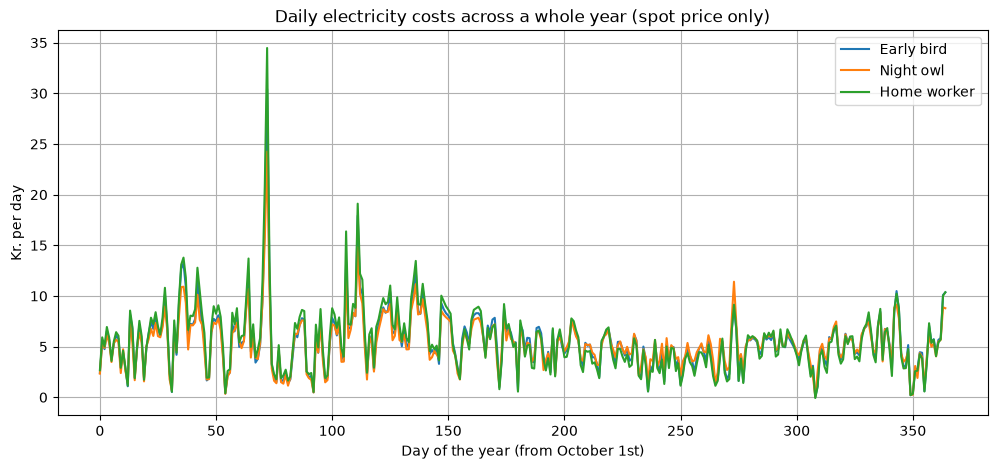

The routine is written once - the matrix mechanics scale to 3 households or 3 million.
But in reality, patterns vary far more between households than three stylised profiles can show.


In [13]:
# The whole year, day by day, all households
plt.figure(figsize=(12, 5))
for i in range(3):
    plt.plot(daily_costs[i], label=names[i])
plt.title("Daily electricity costs across a whole year (spot price only)")
plt.xlabel("Day of the year (from October 1st)")
plt.ylabel("Kr. per day")
plt.legend()
plt.grid(True)
plt.show()

print("The routine is written once - the matrix mechanics scale to 3 households or 3 million.")
print("But in reality, patterns vary far more between households than three stylised profiles can show.")


Notice winter's violent spikes: the most expensive day of the year falls in mid-December - that kind of price spike is typically caused by a combination of cold weather and low wind (for illustration - we do not have weather data here to confirm that for this particular day). The price on the most expensive day can easily be several times the price on an average day. That is the kind of pattern you only see when you look at a whole year at once.


#### Turn the dials

* **Add yourself**: Make your own profile as in Chapter 2, and change the line with `P` to `P = np.array([early_bird, night_owl, home_worker, my_profile])`. Also add a name to the `names` list. Run the cells again - the whole analysis now includes you.
* **Winter's most expensive day**: Create a new cell and write `print(np.argmax(daily_costs[0]))`. The number is the day's index within the year (day 0 = October 1st) - when did it hit?


## Chapter 4 - Denmark's economy as a matrix *(after Lesson 4: Inverse Matrices and Determinants)*

Finally, we zoom all the way out. Sectors in an economy buy from *each other*: the energy sector uses industry's machines, industry uses energy, the service sector uses both. That is exactly the system described by **Leontief's input-output model** from Lesson 4 - and Statistics Denmark maintains the real tables for the whole Danish economy.

Here we use a simplified 3-sector version (the numbers are stylised and rounded; the structure corresponds to Statistics Denmark's input-output tables):


In [14]:
# Input matrix M: column j shows what 1 krone's worth of production in sector j requires from each sector
sectors = ["Energy", "Industry", "Service"]
M = np.array([
    [0.05, 0.08, 0.02],   # energy input
    [0.15, 0.25, 0.10],   # industry input
    [0.20, 0.20, 0.15],   # service input
])

# Final demand (DKK billion) - consumption, exports, etc.
D = np.array([150, 900, 1400])


In [15]:
# Can the system be solved? The determinant decides (Lesson 4)
I = np.identity(3)
det_I_minus_M = np.linalg.det(I - M)
print(f"det(I - M) = {det_I_minus_M:.3f} - different from 0, so the system can be solved")

# Leontief: X = (I - M)^-1 @ D
X = np.linalg.inv(I - M) @ D
for i in range(3):
    print(f"{sectors[i]}: must produce {X[i]:.0f} DKK billion to cover {D[i]} DKK billion of demand")


det(I - M) = 0.571 - different from 0, so the system can be solved
Energy: must produce 332 DKK billion to cover 150 DKK billion of demand
Industry: must produce 1545 DKK billion to cover 900 DKK billion of demand
Service: must produce 2089 DKK billion to cover 1400 DKK billion of demand


In [16]:
# Scenario: demand for energy rises 10% - what happens across the WHOLE economy?
D_new = D.copy()
D_new[0] = D_new[0] * 1.10

X_new = np.linalg.inv(I - M) @ D_new
for i in range(3):
    print(f"{sectors[i]}: {X[i]:.0f} -> {X_new[i]:.0f} DKK billion (+{X_new[i]-X[i]:.1f})")

print("\nNotice: ALL sectors grow - because they supply each other.")


Energy: 332 -> 348 DKK billion (+16.2)
Industry: 1545 -> 1549 DKK billion (+3.9)
Service: 2089 -> 2093 DKK billion (+4.7)

Notice: ALL sectors grow - because they supply each other.


#### Turn the dials

* **More energy-intensive industry**: In the cell with `M`: change `0.08` (first row, second column) to `0.20`, and run all three cells again. How hard does an energy shock hit now?
* **Extremely dependent sectors**: Change all nine numbers in `M` to `0.33`, and run again. Watch `det(I - M)` - the system is starting to "eat itself". Can you see it in the numbers?


## Chapter 5 - Reading the price curve *(after Lesson 5: Functions and Differentiation)*

Back in the opening we fetched today's spot prices and looked at the curve by eye. Now that we know about functions and differentiation, we can describe what we saw more precisely: how fast the price is rising or falling at a given moment is exactly a **slope** - the change in price per hour.


In [17]:
# The slope between two points in time - as in Lesson 5
x1, x2 = 6, 8
slope = (electricity_prices[x2] - electricity_prices[x1]) / (x2 - x1)

if slope > 0:
    print(f"Between {x1}:00 and {x2}:00 the price RISES: {slope:.3f} kr/kWh per hour")
else:
    print(f"Between {x1}:00 and {x2}:00 the price FALLS: {slope:.3f} kr/kWh per hour")

# Also try the afternoon, where the evening peak builds up
x1, x2 = 14, 20
slope = (electricity_prices[x2] - electricity_prices[x1]) / (x2 - x1)

if slope > 0:
    print(f"Between {x1}:00 and {x2}:00 the price RISES: {slope:.3f} kr/kWh per hour")
else:
    print(f"Between {x1}:00 and {x2}:00 the price FALLS: {slope:.3f} kr/kWh per hour")


Between 6:00 and 8:00 the price FALLS: -0.077 kr/kWh per hour
Between 14:00 and 20:00 the price RISES: 0.304 kr/kWh per hour


Fetched fresh spot prices for 2026-08-14 (DK2)


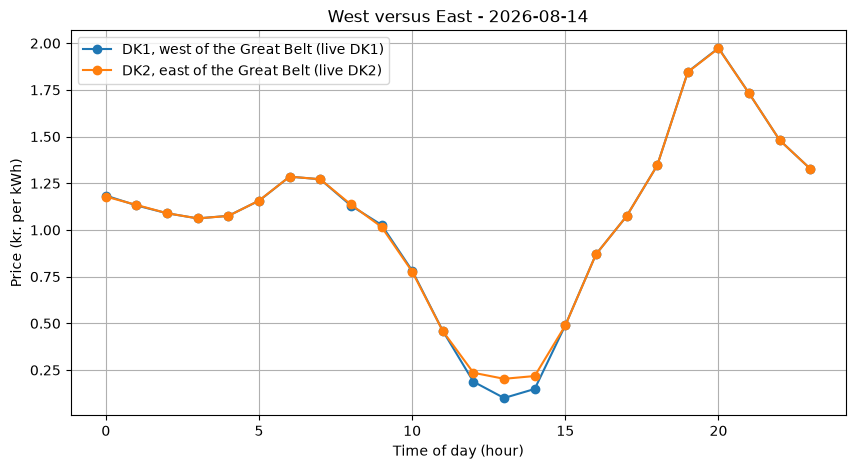

In [18]:
# Fetch eastern Denmark with the same function - just a different input
electricity_prices_dk2, date_dk2, source_dk2 = fetch_electricity_prices("DK2")

if source_dk1 == _SOURCE_FALLBACK and source_dk2 == _SOURCE_FALLBACK:
    print("Could not fetch live data - skipping the area comparison today.")
else:
    plt.figure(figsize=(10, 5))
    plt.plot(hours, electricity_prices, 'o-', label=f"DK1, west of the Great Belt ({source_dk1})")
    plt.plot(hours, electricity_prices_dk2, 'o-', label=f"DK2, east of the Great Belt ({source_dk2})")
    plt.title(f"West versus East - {date}")
    plt.xlabel("Time of day (hour)")
    plt.ylabel("Price (kr. per kWh)")
    plt.legend()
    plt.grid(True)
    plt.show()


Are the two curves almost on top of each other? That is not a mistake: when the transmission cables between the two parts of the country are not fully loaded, the whole of Denmark shares one price. On days with a lot of wind or high demand, the curves separate - so there is, quite literally, a difference between living in Aalborg and in Copenhagen.


#### Turn the dials

* **Try the neighbourhood**: Create a new cell (the `+ Code` button) and write, for example, `prices_norway, d, source = fetch_electricity_prices("NO2")` - and plot it just like above. Is Norwegian hydropower cheaper than Danish wind today?
* **Measure other slopes**: In the slope cell, change `x1, x2 = 6, 8` to two other times of day (e.g. `10, 13`), and run the cell again.
* **No code at all**: Read the graphs - when would you start the dishwasher today? And is the answer the same in east and west?


### To be continued
The case grows with the course: the next chapter unlocks after **Lesson 6** - Inflation and your fixed expenses